# Evolución del modelo — ¿Qué hueso es? (PyConES 2026)

Lee directamente el experimento `pycon26-evolucion-bone-group` de MLflow (55 runs,
reconstrucción retroactiva de todos los hitos de `base_datos_osea/HISTORIAL.md`) y genera
las gráficas de la charla como PNG, sin depender de HTML/SVG a mano.


In [1]:
import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

mlflow.set_tracking_uri("sqlite:///../mlruns_local/mlflow.db")

OUT_DIR = Path("output")
OUT_DIR.mkdir(exist_ok=True)

EXPERIMENT_NAME = "pycon26-evolucion-bone-group"
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
assert exp is not None, f"No existe el experimento {EXPERIMENT_NAME} — ejecuta antes los scripts que lo cargan"

runs = mlflow.search_runs(experiment_ids=[exp.experiment_id], order_by=["start_time ASC"])
print(f"{len(runs)} runs cargados de '{EXPERIMENT_NAME}'")
runs.head()

/root/dev/osteolab-ml-platform/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


91 runs cargados de 'pycon26-evolucion-bone-group'


,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.accuracy,metrics.recall_macro,metrics.precision_macro,metrics.f1_macro,...,tags.descartado,tags.fecha_sesion,tags.notas,tags.banco_fotos,tags.fase,tags.dominio_datos,tags.reevaluado_hoy,tags.conclusion_calibrada,tags.n_fotos_reales_objetivo,tags.tiene_sinteticos
0,8739ab561f8c476fb0829b7787d3d282,5,FINISHED,/root/dev/osteolab-ml-platform/mlruns/5/8739ab...,2026-07-23 00:00:00+00:00,2026-07-23 00:00:01+00:00,0.838,NaN,NaN,NaN,...,True,2026-07-23,"Split por fila, optimista: fuga de especimenes...",n/a,0-exploracion,sintetico_fuga,None,None,None,None
1,779f23a3fc4449d482598a8715deb944,5,FINISHED,/root/dev/osteolab-ml-platform/mlruns/5/779f23...,2026-07-23 00:00:01+00:00,2026-07-23 00:00:02+00:00,0.655,NaN,NaN,NaN,...,False,2026-07-23,GroupKFold especimen-fuera: primera medicion h...,n/a,0-exploracion,sintetico,None,None,None,None
2,614b881f2590476db2d6689c7bae82e4,5,FINISHED,/root/dev/osteolab-ml-platform/mlruns/5/614b88...,2026-07-23 00:16:40+00:00,2026-07-23 00:16:41+00:00,0.671,0.47,0.5,0.46,...,False,2026-07-23,Primer experimento de la charla: ResNet18 (Lin...,"3728 (3653 sinteticas + 75 reales, 0% reales e...",0-exploracion,mixto_75pct_sintetico,None,None,None,None
3,0293ce51910e4c839bba092fdad86095,5,FINISHED,/root/dev/osteolab-ml-platform/mlruns/5/0293ce...,2026-07-24 00:00:02+00:00,2026-07-24 00:00:03+00:00,0.280,NaN,NaN,NaN,...,False,2026-07-24,Primer banco de fotos reales. Domain gap bruta...,25 (3 grupos),1-primer-contacto-real,real,None,None,None,None
4,df687e9a776c48a9b97b0e28738dd350,5,FINISHED,/root/dev/osteolab-ml-platform/mlruns/5/df687e...,2026-07-24 00:00:03+00:00,2026-07-24 00:00:04+00:00,0.400,NaN,NaN,NaN,...,False,2026-07-24,Fix de segmentacion combinada sobre el primer ...,25 (3 grupos),1-primer-contacto-real,real,None,None,None,None


## Limpieza

Columnas `metrics.*`, `params.*`, `tags.*` que trae `search_runs`. Nos quedamos con las que
interesan y ordenamos por fecha real de la sesión (tag `fecha_sesion`, no por `start_time`
bruto, que lleva un offset artificial para poder ordenar runs del mismo día).

In [2]:
keep = [c for c in runs.columns if c.startswith("metrics.") or c in (
    "tags.mlflow.runName", "tags.fase", "tags.modelo", "tags.dominio_datos",
    "tags.banco_fotos", "tags.fecha_sesion", "tags.descartado", "tags.notas", "start_time",
)]
df = runs[keep].copy()
df.columns = [c.replace("metrics.", "").replace("tags.mlflow.runName", "run_name").replace("tags.", "") for c in df.columns]
df["descartado"] = df["descartado"].fillna("False") == "True"
df = df.sort_values("start_time").reset_index(drop=True)
df.to_csv(OUT_DIR / "pycon26_runs.csv", index=False)
df[["run_name", "fecha_sesion", "fase", "accuracy", "balanced_accuracy", "descartado"]]

,run_name,fecha_sesion,fase,accuracy,balanced_accuracy,descartado
0,pycon26-geometrico-split-fila-fuga,2026-07-23,0-exploracion,0.838000,NaN,True
1,pycon26-geometrico-groupkfold-honesto,2026-07-23,0-exploracion,0.655000,NaN,False
2,pycon26-resnet18-primer-experimento,2026-07-23,0-exploracion,0.671000,NaN,False
3,pycon26-primer-banco-real,2026-07-24,1-primer-contacto-real,0.280000,NaN,False
4,pycon26-fix-segmentacion-combinada,2026-07-24,1-primer-contacto-real,0.400000,NaN,False
...,...,...,...,...,...,...
86,pycon26-ablation-real25-synth,2026-10-25,18-curva-ablacion-pocas-fotos,0.831325,0.846914,False
87,pycon26-ablation-real50,2026-10-25,18-curva-ablacion-pocas-fotos,0.771084,0.682099,False
88,pycon26-ablation-real50-synth,2026-10-25,18-curva-ablacion-pocas-fotos,0.783133,0.809568,False
89,pycon26-ablation-real100,2026-10-25,18-curva-ablacion-pocas-fotos,0.759036,0.725000,False


## Gráfica 0 — TODOS los experimentos (55 runs), no solo el hilo principal

La "curva principal" de la Gráfica 1 es un recorte curado de 10 hitos para contar la historia
en una diapositiva. Aquí va la comparación completa: cada run del experimento, en orden
cronológico, coloreado por fase, con los descartados marcados aparte (rayado + borde rojo) —
así se ve también lo que NO funcionó, no solo lo que se quedó.

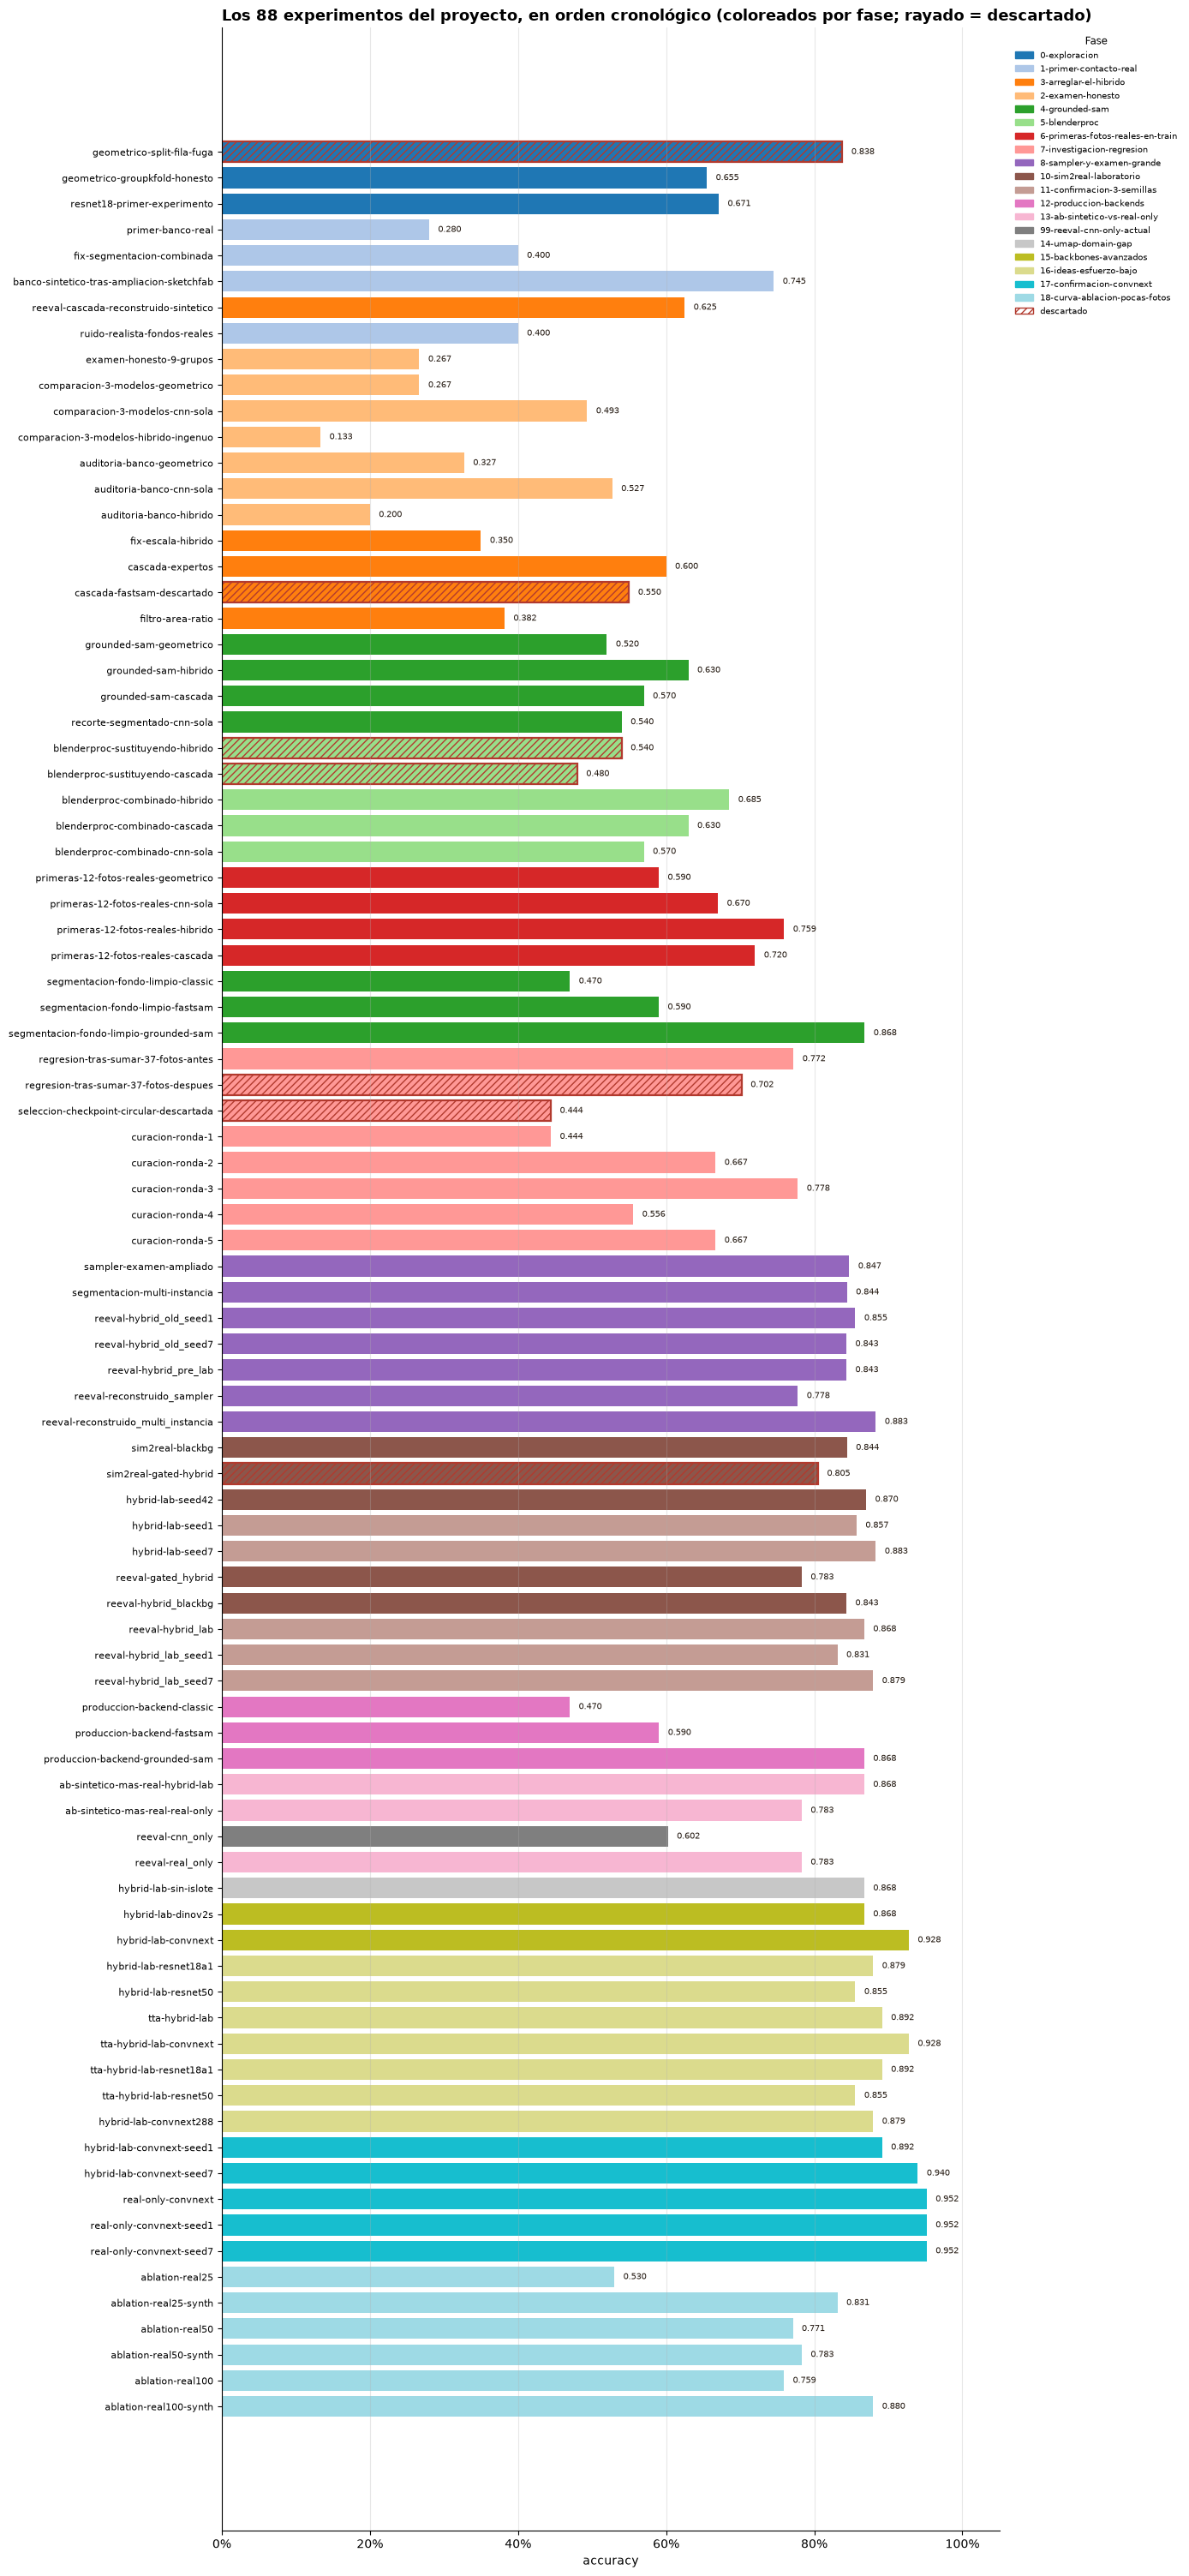

In [3]:
import matplotlib.patches as mpatches
import matplotlib.cm as cm

full = df[df["accuracy"].notna()].copy()
full = full.sort_values("start_time").reset_index(drop=True)
full["short_name"] = full["run_name"].str.replace("pycon26-", "", regex=False)

fases = full["fase"].drop_duplicates().tolist()
palette = plt.colormaps.get_cmap("tab20").resampled(len(fases))
fase_color = {f: palette(i) for i, f in enumerate(fases)}

fig, ax = plt.subplots(figsize=(14, 0.32 * len(full) + 2))

y = range(len(full))
colors = [fase_color[f] for f in full["fase"]]
edge_colors = ["#b23a2e" if d else "none" for d in full["descartado"]]
hatches = ["////" if d else None for d in full["descartado"]]

bars = ax.barh(list(y), full["accuracy"], color=colors, edgecolor=edge_colors, linewidth=1.6)
for bar, h in zip(bars, hatches):
    if h:
        bar.set_hatch(h)

for yi, (acc, name) in enumerate(zip(full["accuracy"], full["short_name"])):
    ax.text(acc + 0.012, yi, f"{acc:.3f}", va="center", fontsize=7.5, color="#241a12")

ax.set_yticks(list(y))
ax.set_yticklabels(full["short_name"], fontsize=7.8)
ax.invert_yaxis()  # cronológico de arriba a abajo
ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_xlabel("accuracy")
ax.set_title(
    f"Los {len(full)} experimentos del proyecto, en orden cronológico (coloreados por fase; "
    "rayado = descartado)",
    fontsize=13, fontweight="bold", loc="left",
)
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fase_handles = [mpatches.Patch(color=fase_color[f], label=f) for f in fases]
descartado_handle = mpatches.Patch(facecolor="white", edgecolor="#b23a2e", hatch="////", label="descartado")
ax.legend(handles=fase_handles + [descartado_handle], bbox_to_anchor=(1.01, 1), loc="upper left",
          fontsize=7.5, frameon=False, title="Fase", title_fontsize=8.5)

fig.tight_layout()
fig.savefig(OUT_DIR / "00_todos_los_experimentos.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## Gráfica 0b — cómo varía dentro de cada fase

La Gráfica 0 ya muestra los 54 experimentos en una sola barra cronológica. Aquí se parte la
misma información en un panel por fase (las 13 fases con las que se etiquetó cada run en
MLflow), cada uno con sus propios runs en orden, para ver el detalle de cómo subió o bajó la
métrica DENTRO de esa fase concreta — sin los números pisándose unos a otros.

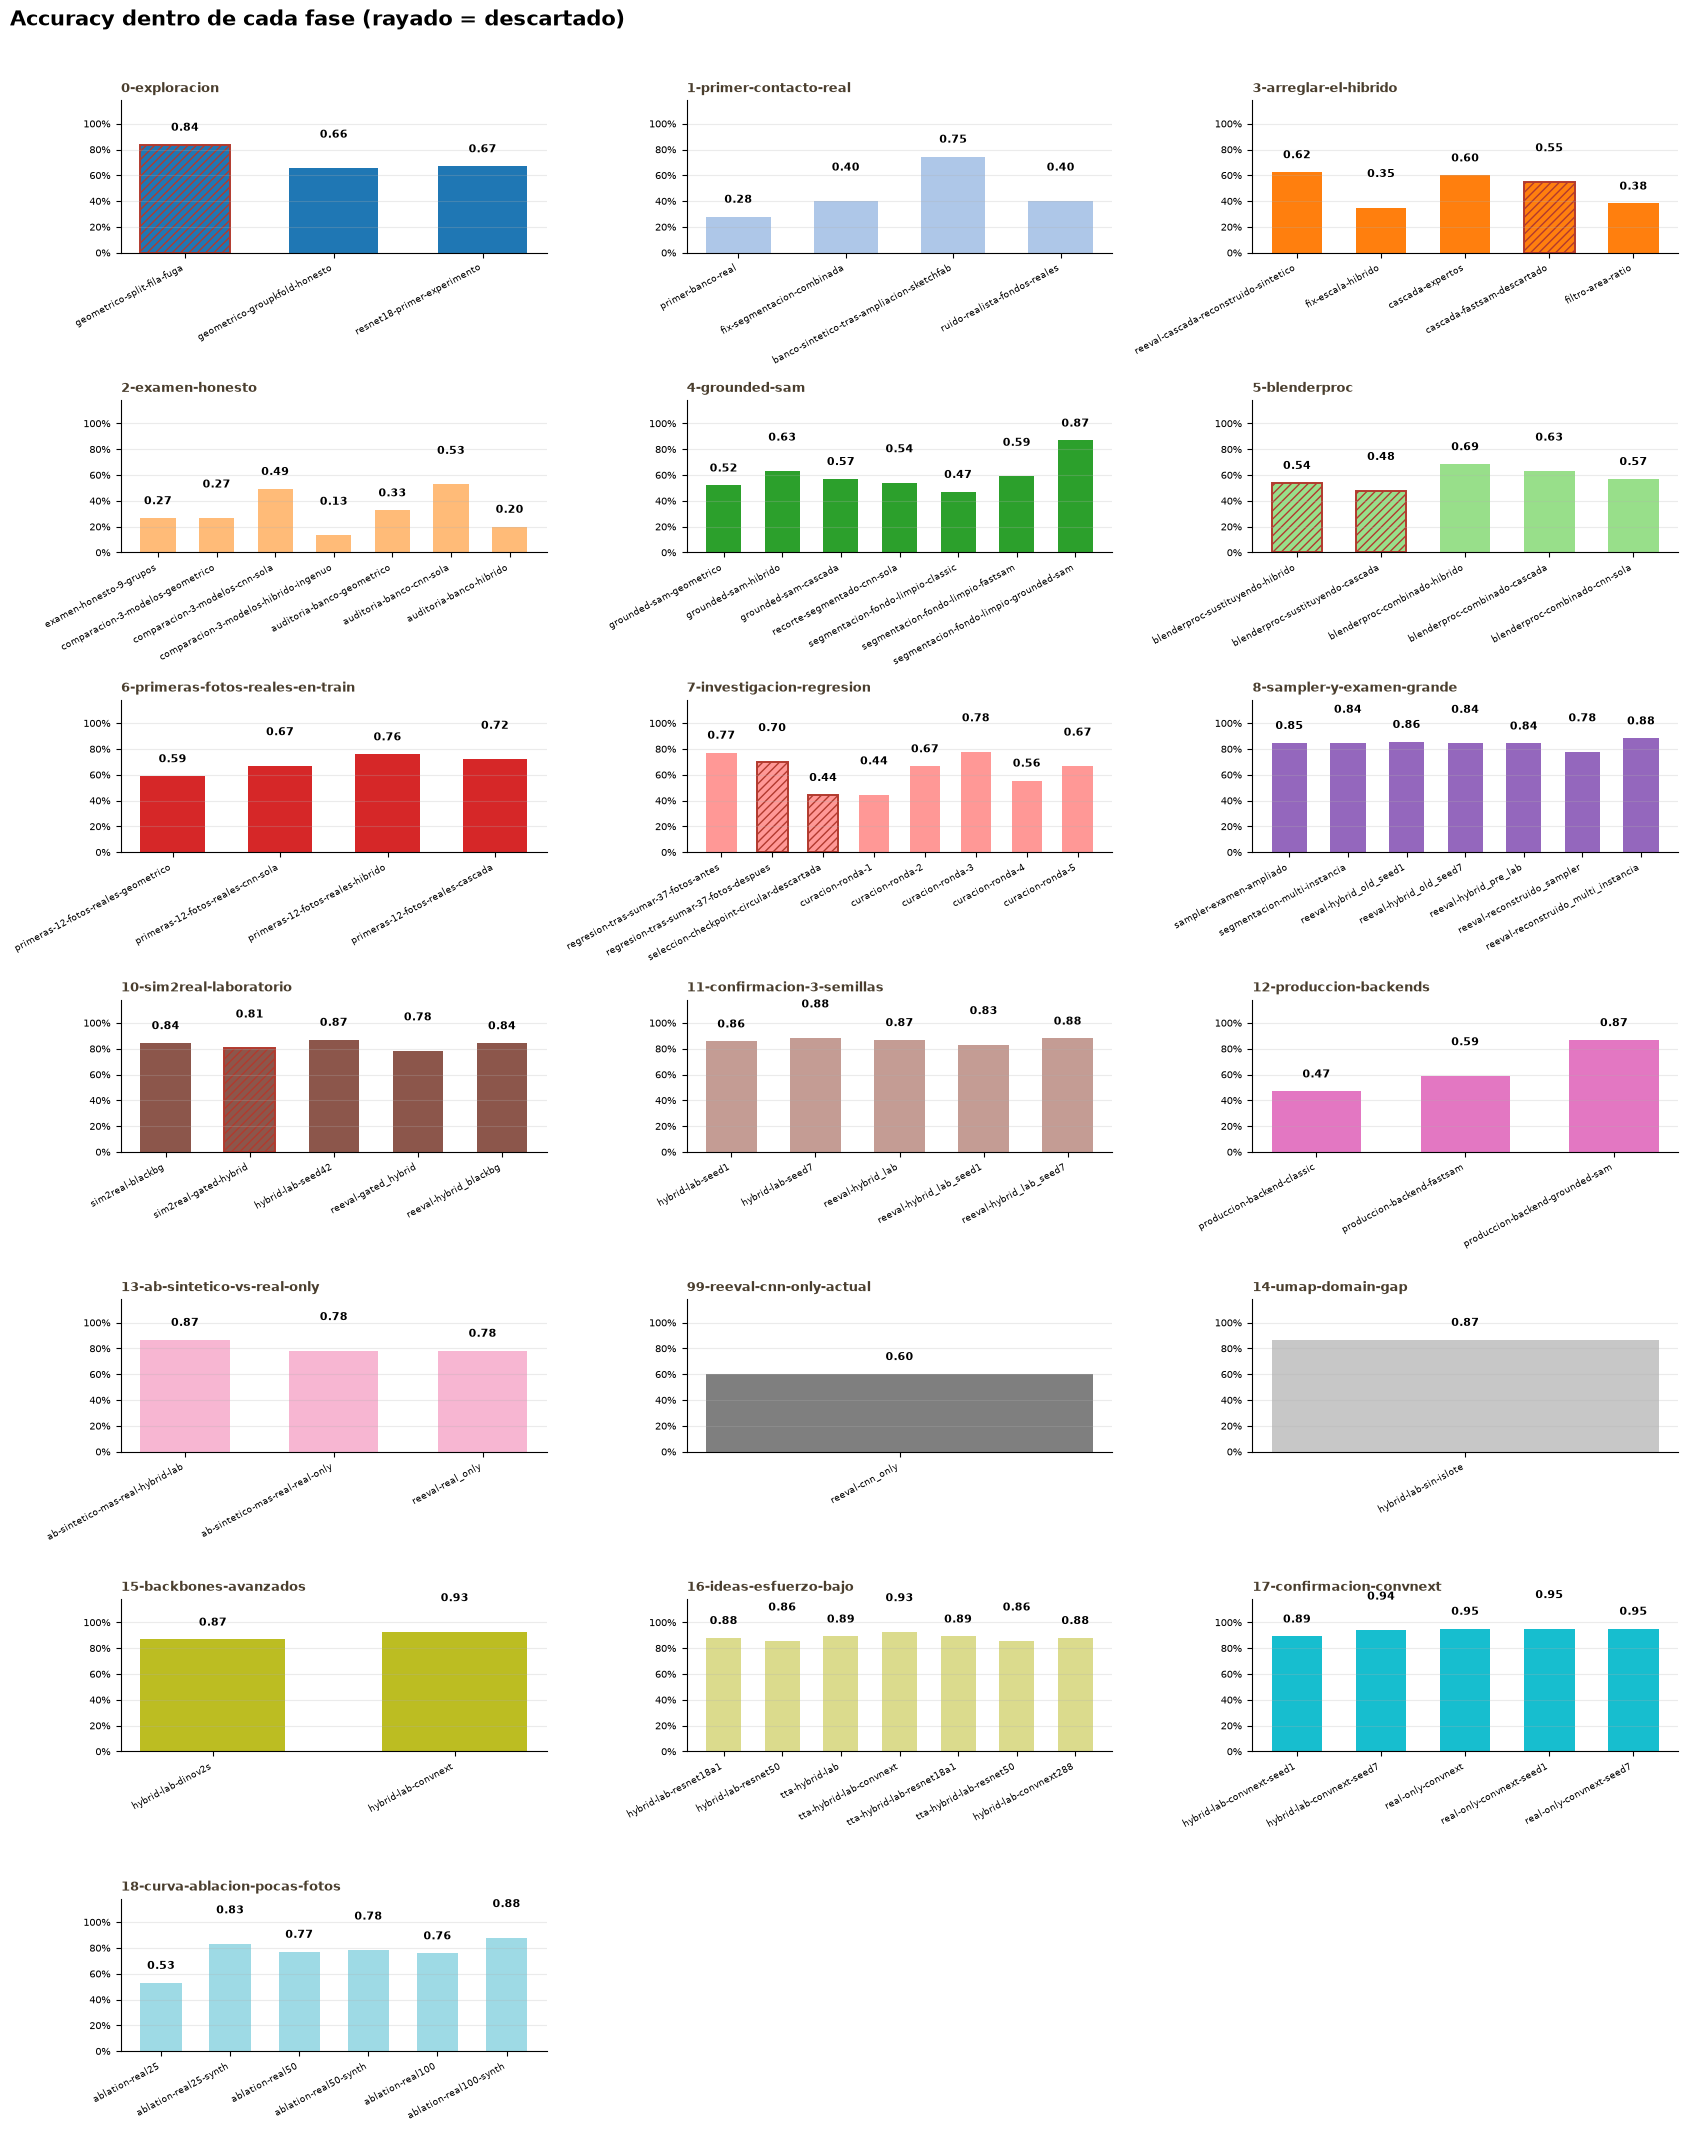

In [4]:
fases_orden = (
    df[df["accuracy"].notna()]
    .sort_values("start_time")["fase"]
    .drop_duplicates()
    .tolist()
)
n_fases = len(fases_orden)
n_cols = 3
n_rows = -(-n_fases // n_cols)  # ceil

fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 3.1 * n_rows))
axes = axes.flatten()

for ax, fase in zip(axes, fases_orden):
    sub = df[(df["fase"] == fase) & df["accuracy"].notna()].sort_values("start_time").reset_index(drop=True)
    sub["short_name"] = sub["run_name"].str.replace("pycon26-", "", regex=False)
    xi = range(len(sub))
    edge = ["#b23a2e" if d else "none" for d in sub["descartado"]]
    hatch = ["////" if d else None for d in sub["descartado"]]
    bars = ax.bar(xi, sub["accuracy"], color=fase_color[fase], edgecolor=edge, linewidth=1.4, width=0.6)
    for b, h in zip(bars, hatch):
        if h:
            b.set_hatch(h)
    # alterna el label arriba/abajo del valor para que no se pisen en fases con barras muy juntas
    for j, (xi_, yi_) in enumerate(zip(xi, sub["accuracy"])):
        dy = 10 if j % 2 == 0 else 22
        ax.annotate(f"{yi_:.2f}", (xi_, yi_), textcoords="offset points", xytext=(0, dy),
                    ha="center", fontsize=7.6, fontweight="bold")
    ax.set_xticks(list(xi))
    ax.set_xticklabels(sub["short_name"], fontsize=6.6, rotation=28, ha="right")
    ax.set_ylim(0, 1.18)
    ax.set_title(fase, fontsize=9.5, fontweight="bold", loc="left", color="#4a3e2e")
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.tick_params(axis="y", labelsize=7)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[n_fases:]:
    ax.axis("off")

fig.suptitle("Accuracy dentro de cada fase (rayado = descartado)", fontsize=15, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(OUT_DIR / "00b_por_fase.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 1 — curva principal: accuracy + balanced accuracy

Solo los runs de la serie principal (no descartados, con `accuracy` sobre fotos reales),
en el orden cronológico real. `balanced_accuracy` solo existe desde el sampler
(2026-08-03 en adelante) — se traza desde ahí, no se inventa antes.

In [5]:
MAIN_SPINE = [
    "pycon26-primer-banco-real",
    "pycon26-comparacion-3-modelos-cnn-sola",
    "pycon26-cascada-expertos",
    "pycon26-grounded-sam-hibrido",
    "pycon26-blenderproc-combinado-hibrido",
    "pycon26-primeras-12-fotos-reales-hibrido",
    "pycon26-sampler-examen-ampliado",
    "pycon26-segmentacion-multi-instancia",
    "pycon26-hybrid-lab-seed42",
    "pycon26-ab-sintetico-mas-real-hybrid-lab",
]
LABELS = [
    "Geométrico\n1er banco real", "CNN sola\nresnet18", "Cascada\nelongación+CNN",
    "Híbrido\nGrounded-SAM", "Híbrido\n+BlenderProc", "Híbrido\n+12 fotos reales",
    "Híbrido\n+Sampler", "Híbrido\nmulti-instancia", "hybrid_lab\nlaboratorio",
    "hybrid_lab\nproducción (83 fotos)",
]
BANCO = ["25 fotos", "55 fotos", "55 fotos", "54 fotos", "54 fotos", "54 fotos",
         "72 fotos", "77 fotos", "77 fotos", "83 fotos"]

spine = df.set_index("run_name").loc[MAIN_SPINE].reset_index()
spine["label"] = LABELS
spine["banco"] = BANCO
spine

,run_name,start_time,accuracy,recall_macro,precision_macro,f1_macro,balanced_accuracy,recall_weighted,top3_accuracy,f1_weighted,...,ninguno,modelo,descartado,fecha_sesion,notas,banco_fotos,fase,dominio_datos,label,banco
0,pycon26-primer-banco-real,2026-07-24 00:00:02+00:00,0.2800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,geometrico,False,2026-07-24,Primer banco de fotos reales. Domain gap bruta...,25 (3 grupos),1-primer-contacto-real,real,Geométrico\n1er banco real,25 fotos
1,pycon26-comparacion-3-modelos-cnn-sola,2026-07-25 00:00:08+00:00,0.4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,cnn_only_resnet18,False,2026-07-25,"CNN sola (resnet18), la que de verdad ayuda en...",75,2-examen-honesto,real,CNN sola\nresnet18,55 fotos
2,pycon26-cascada-expertos,2026-07-25 00:00:14+00:00,0.6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,cascada_elongacion_cnn,False,2026-07-25,"Mixture-of-experts: elongacion->hueso_largo, r...",55,3-arreglar-el-hibrido,real,Cascada\nelongación+CNN,55 fotos
3,pycon26-grounded-sam-hibrido,2026-07-26 00:00:18+00:00,0.6300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,hibrido,False,2026-07-26,Grounded-SAM: arregla casos con huecos centrad...,54,4-grounded-sam,real,Híbrido\nGrounded-SAM,54 fotos
4,pycon26-blenderproc-combinado-hibrido,2026-07-26 00:00:23+00:00,0.6852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,hibrido,False,2026-07-26,BlenderProc SUMADO (no sustituido) al pipeline...,54,5-blenderproc,real,Híbrido\n+BlenderProc,54 fotos
5,pycon26-primeras-12-fotos-reales-hibrido,2026-07-26 00:00:28+00:00,0.7593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,hibrido,False,2026-07-26,El mayor salto de la sesion: 12 fotos reales m...,54,6-primeras-fotos-reales-en-train,real,Híbrido\n+12 fotos reales,54 fotos
6,pycon26-sampler-examen-ampliado,2026-08-03 00:00:38+00:00,0.8472,NaN,NaN,NaN,0.7631,NaN,NaN,NaN,...,NaN,hibrido,False,2026-08-03,WeightedRandomSampler x4 en fotos reales + exa...,72,8-sampler-y-examen-grande,real,Híbrido\n+Sampler,72 fotos
7,pycon26-segmentacion-multi-instancia,2026-08-03 00:00:39+00:00,0.8442,NaN,NaN,NaN,0.7959,NaN,NaN,NaN,...,NaN,hibrido,False,2026-08-03,Separa huesos sueltos en la misma foto automat...,77,8-sampler-y-examen-grande,real,Híbrido\nmulti-instancia,77 fotos
8,pycon26-hybrid-lab-seed42,2026-08-13 00:00:43+00:00,0.8701,NaN,NaN,NaN,0.8323,NaN,NaN,NaN,...,NaN,hybrid_lab,False,2026-08-13,"Escena de laboratorio (caida fisica, luz de es...",77,10-sim2real-laboratorio,real,hybrid_lab\nlaboratorio,77 fotos
9,pycon26-ab-sintetico-mas-real-hybrid-lab,2026-10-25 00:00:49+00:00,0.8675,NaN,NaN,NaN,0.8315,NaN,0.9759,NaN,...,NaN,hybrid_lab,False,2026-10-25,Prueba A/B pedida para la charla: hybrid_lab c...,83,13-ab-sintetico-vs-real-only,sintetico+real,hybrid_lab\nproducción (83 fotos),83 fotos


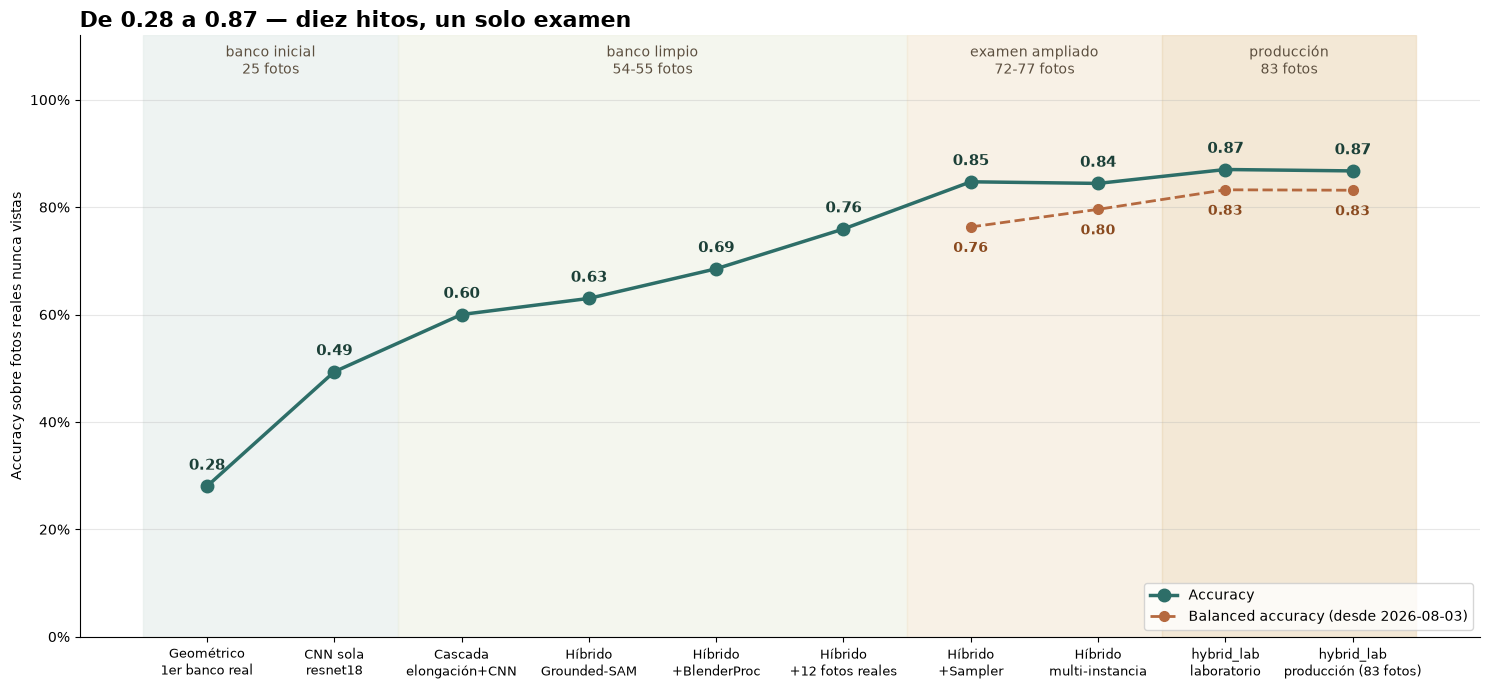

In [6]:
fig, ax = plt.subplots(figsize=(15, 7))

x = range(len(spine))
ax.plot(x, spine["accuracy"], marker="o", markersize=9, linewidth=2.5,
        color="#2d6e68", label="Accuracy")

bal = spine["balanced_accuracy"]
bal_mask = bal.notna()
ax.plot([xi for xi, m in zip(x, bal_mask) if m], bal[bal_mask],
        marker="o", markersize=7, linewidth=2, linestyle="--",
        color="#b5693f", label="Balanced accuracy (desde 2026-08-03)")

# bandas de fondo por tamaño de banco de examen
band_edges = [-0.5, 1.5, 5.5, 7.5, 9.5]
band_colors = ["#e4ecea", "#eef0e3", "#f4e9d6", "#ecd9bc"]
band_labels = ["banco inicial\n25 fotos", "banco limpio\n54-55 fotos",
               "examen ampliado\n72-77 fotos", "producción\n83 fotos"]
for i in range(4):
    ax.axvspan(band_edges[i], band_edges[i + 1], color=band_colors[i], alpha=0.6, zorder=0)
    mid = (band_edges[i] + band_edges[i + 1]) / 2
    ax.text(mid, 1.04, band_labels[i], ha="center", va="bottom", fontsize=10, color="#5c4f3f")

for xi, yi in zip(x, spine["accuracy"]):
    ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=11, fontweight="bold", color="#1c4038")
for xi, yi, m in zip(x, bal, bal_mask):
    if m:
        ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, -18),
                    ha="center", fontsize=10, fontweight="bold", color="#8a4a1f")

ax.set_xticks(list(x))
ax.set_xticklabels(spine["label"], fontsize=9.5)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_ylabel("Accuracy sobre fotos reales nunca vistas")
ax.set_title("De 0.28 a 0.87 — diez hitos, un solo examen", fontsize=16, fontweight="bold", loc="left")
ax.legend(loc="lower right", fontsize=10, frameon=True)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "01_curva_accuracy.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 1b — las 4 métricas principales, en el mismo eje temporal

Mismo recorrido cronológico que la Gráfica 1 (geométrico → resnet18 → cascada → Grounded-SAM →
BlenderProc → +fotos reales → sampler → multi-instancia → hybrid_lab → producción), pero ahora
en un panel por métrica: **accuracy, precisión, recall, F1**.

Importante y honesto con lo que hay en MLflow: **accuracy** se midió en los diez hitos.
**Precisión/recall/F1 macro** solo se midieron en dos momentos puntuales de toda la serie
(el baseline ResNet18 y la comparación de backends de segmentación) — se marcan como puntos
sueltos sobre el hito más cercano, con una ★ y la nota de qué banco se usó, en vez de inventar
una línea continua con datos que nunca se calcularon en los demás pasos.

In [7]:
import numpy as np

dfi = df.set_index("run_name")

GRUPOS = ["costilla", "cranio", "hueso_largo", "hueso_pequeno", "hueso_plano",
          "mandibula_maxilar", "pelvis", "sacro", "vertebra"]

def macro_from_groups(run_name, prefix):
    """Media de las columnas recall_<grupo>/precision_<grupo> que existan para ese run."""
    cols = [f"{prefix}_{g}" for g in GRUPOS if f"{prefix}_{g}" in dfi.columns]
    vals = dfi.loc[run_name, cols].dropna()
    return (vals.mean(), len(vals)) if len(vals) else (np.nan, 0)

def macro_f1_from_groups(run_name):
    """F1 por grupo = 2PR/(P+R), promediado -- solo donde hay precision Y recall del mismo grupo."""
    f1s = []
    for g in GRUPOS:
        p, r = dfi.loc[run_name].get(f"precision_{g}"), dfi.loc[run_name].get(f"recall_{g}")
        if pd.notna(p) and pd.notna(r) and (p + r) > 0:
            f1s.append(2 * p * r / (p + r))
    return (float(np.mean(f1s)), len(f1s)) if f1s else (np.nan, 0)

# puntos REALES adicionales, calculados a partir de las metricas por grupo ya logueadas
# (no se inventa nada: cada punto es la media de columnas recall_X/precision_X del propio run)
recall_seed42, n_r42 = macro_from_groups("pycon26-hybrid-lab-seed42", "recall")
recall_today, n_rtoday = macro_from_groups("pycon26-ab-sintetico-mas-real-hybrid-lab", "recall")
precision_today, n_ptoday = macro_from_groups("pycon26-ab-sintetico-mas-real-hybrid-lab", "precision")
f1_today, n_f1today = macro_f1_from_groups("pycon26-ab-sintetico-mas-real-hybrid-lab")

print(f"recall macro  hybrid_lab-seed42 (n={n_r42} grupos):   {recall_seed42:.3f}")
print(f"recall macro  hoy, producción   (n={n_rtoday} grupos): {recall_today:.3f}")
print(f"precision macro hoy, producción (n={n_ptoday} grupos): {precision_today:.3f}")
print(f"F1 macro      hoy, producción   (n={n_f1today} grupos): {f1_today:.3f}")

recall macro  hybrid_lab-seed42 (n=8 grupos):   0.842
recall macro  hoy, producción   (n=9 grupos): 0.831
precision macro hoy, producción (n=9 grupos): 0.850
F1 macro      hoy, producción   (n=9 grupos): 0.810


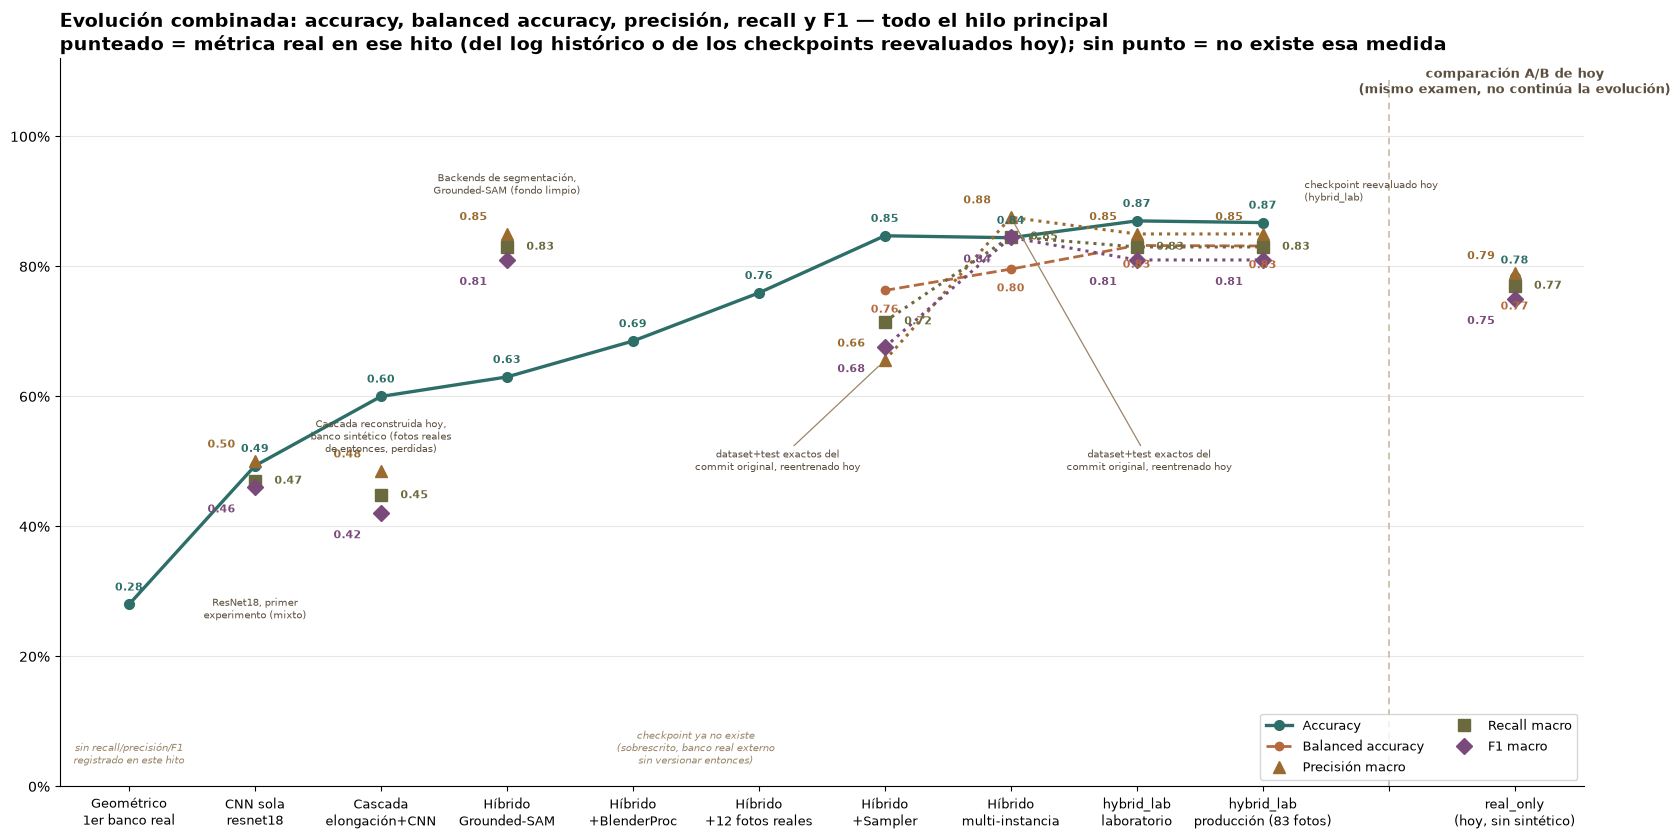

In [8]:
import json

reeval = json.load(open("/tmp/claude-0/-root-dev-osteolab-ml-platform/4952efa4-7606-4057-90ab-fe4d76a28420/scratchpad/reeval_parsed.json"))

# eje temporal: el hilo principal de siempre + un hueco visual + el A/B de hoy, separado
# aparte -- real_only NO es una continuacion de la evolucion, es una comparacion puntual
# contra hybrid_lab (mismo examen, mismo checkpoint arquitectura, solo cambia el dataset de
# entrenamiento) y conectarlo con una linea da a entender una caida en la tendencia que no
# existe como tal.
labels_full = list(spine["label"]) + ["", "real_only\n(hoy, sin sintético)"]
x = list(range(len(labels_full)))
IDX_RESNET18, IDX_CASCADA, IDX_GSAM_BACKEND, IDX_SAMPLER, IDX_MULTI_INST, IDX_HYBRID_LAB, IDX_PROD, IDX_GAP, IDX_REAL_ONLY = 1, 2, 3, 6, 7, 8, 9, 10, 11

fig, ax = plt.subplots(figsize=(17, 8.5))

# -- accuracy / balanced accuracy: serie completa (igual que antes) + el punto final de hoy --
acc_x = x[:len(spine)]
acc_y = list(spine["accuracy"])
ax.plot(acc_x, acc_y, marker="o", markersize=7, linewidth=2.4, color="#2d6e68", label="Accuracy")
for xi, yi in zip(acc_x, acc_y):
    ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=8.2, fontweight="bold", color="#2d6e68")
# punto de referencia hybrid_lab (mismo checkpoint que "producción") + real_only, lado a lado,
# SIN linea que los conecte con el resto -- es una comparacion A/B, no una continuacion
ax.plot([IDX_REAL_ONLY], [reeval["real_only"]["accuracy"]], marker="o", markersize=7,
        linestyle="none", color="#2d6e68")
ax.annotate(f"{reeval['real_only']['accuracy']:.2f}", (IDX_REAL_ONLY, reeval["real_only"]["accuracy"]),
            textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8.2,
            fontweight="bold", color="#2d6e68")

bal_mask = spine["balanced_accuracy"].notna()
bal_x = [xi for xi, m in zip(x[:len(spine)], bal_mask) if m]
bal_y = list(spine.loc[bal_mask, "balanced_accuracy"])
ax.plot(bal_x, bal_y, marker="o", markersize=6, linewidth=2, linestyle="--", color="#b5693f", label="Balanced accuracy")
for xi, yi in zip(bal_x, bal_y):
    ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, -16),
                ha="center", fontsize=8, fontweight="bold", color="#b5693f")
ax.plot([IDX_REAL_ONLY], [reeval["real_only"]["balanced_accuracy"]], marker="o", markersize=6,
        linestyle="none", color="#b5693f")
ax.annotate(f"{reeval['real_only']['balanced_accuracy']:.2f}", (IDX_REAL_ONLY, reeval["real_only"]["balanced_accuracy"]),
            textcoords="offset points", xytext=(0, -16), ha="center", fontsize=8,
            fontweight="bold", color="#b5693f")

# -- precision / recall / F1 macro: TODOS los puntos donde se midieron de verdad --
# resnet18 y backends-fondo-limpio -> directo del log historico
# multi-instancia -> checkpoint hybrid_pre_lab reevaluado hoy (era post-sampler+multi-instancia)
# producción (83 fotos) -> checkpoint hybrid_lab reevaluado hoy
# real_only -> checkpoint real_only reevaluado hoy
dfi = df.set_index("run_name")
pts_x = [IDX_RESNET18, IDX_CASCADA, IDX_GSAM_BACKEND, IDX_SAMPLER, IDX_MULTI_INST, IDX_PROD, IDX_REAL_ONLY]

dfi = df.set_index("run_name")
cascada_row = dfi.loc["pycon26-reeval-cascada-reconstruido-sintetico"]
sampler_row = dfi.loc["pycon26-reeval-reconstruido_sampler"]
multi_inst_row = dfi.loc["pycon26-reeval-reconstruido_multi_instancia"]

prec_y = [dfi.loc["pycon26-resnet18-primer-experimento", "precision_macro"],
          cascada_row["precision_macro"],
          dfi.loc["pycon26-segmentacion-fondo-limpio-grounded-sam", "precision_macro"],
          sampler_row["precision_macro"],
          multi_inst_row["precision_macro"],
          reeval["hybrid_lab"]["precision_macro"],
          reeval["real_only"]["precision_macro"]]
rec_y = [dfi.loc["pycon26-resnet18-primer-experimento", "recall_macro"],
         cascada_row["recall_macro"],
         dfi.loc["pycon26-segmentacion-fondo-limpio-grounded-sam", "recall_macro"],
         sampler_row["recall_macro"],
         multi_inst_row["recall_macro"],
         reeval["hybrid_lab"]["recall_macro"],
         reeval["real_only"]["recall_macro"]]
f1_y = [dfi.loc["pycon26-resnet18-primer-experimento", "f1_macro"],
        cascada_row["f1_macro"],
        dfi.loc["pycon26-segmentacion-fondo-limpio-grounded-sam", "f1_macro"],
        sampler_row["f1_macro"],
        multi_inst_row["f1_macro"],
        reeval["hybrid_lab"]["f1_macro"],
        reeval["real_only"]["f1_macro"]]

# IMPORTANTE: pts_x tiene huecos reales (indices 0,2,4,5,6 sin medida) -- conectar todos
# los puntos con una sola linea haria que el segmento pasara VISUALMENTE por encima de esos
# huecos (ej. de resnet18 a los backends de segmentacion, cruzando sobre "Cascada" sin dato),
# dando a entender que hay una tendencia medida donde no la hay. Se agrupan en "clusters" de
# puntos consecutivos de verdad (sin hueco entre ellos) y solo se traza linea DENTRO de cada
# cluster; entre clusters, puntos sueltos sin conectar.
clusters = [[0], [1], [2], [3], [4]]  # cada indice de pts_x por separado, por defecto aislado
# los unicos dos puntos sin hueco real entre si son "multi-instancia" (idx7) y "producción" (idx9)
# -- pero entre ellos esta "laboratorio" (idx8), que es EL MISMO checkpoint hybrid_lab que
# "producción": se añade tambien ahi para no romper la linea con un hueco que en realidad no existe.
pts_x_plot = [IDX_RESNET18, IDX_CASCADA, IDX_GSAM_BACKEND, IDX_SAMPLER, IDX_MULTI_INST, IDX_HYBRID_LAB, IDX_PROD, IDX_REAL_ONLY]
prec_y_plot = [prec_y[0], prec_y[1], prec_y[2], prec_y[3], prec_y[4], reeval["hybrid_lab"]["precision_macro"], prec_y[5], prec_y[6]]
rec_y_plot = [rec_y[0], rec_y[1], rec_y[2], rec_y[3], rec_y[4], reeval["hybrid_lab"]["recall_macro"], rec_y[5], rec_y[6]]
f1_y_plot = [f1_y[0], f1_y[1], f1_y[2], f1_y[3], f1_y[4], reeval["hybrid_lab"]["f1_macro"], f1_y[5], f1_y[6]]
# clusters conectados: (resnet18) aislado, (cascada) aislado, (backends) aislado,
# (sampler, multi-instancia, laboratorio, producción) juntos -- sin hueco real entre ellos,
# todo reconstruido/reevaluado hoy con datasets y checkpoints exactos -- (real_only) aislado
segments = [[0], [1], [2], [3, 4, 5, 6], [7]]  # indices sobre las listas *_plot

def plot_metric(ax, x_src, y_src, marker, color, label, dy, ha):
    first = True
    for seg in segments:
        xs = [x_src[i] for i in seg]
        ys = [y_src[i] for i in seg]
        ax.plot(xs, ys, marker=marker, markersize=9 if marker != "D" else 8, linewidth=2.2,
                 linestyle=":" if len(xs) > 1 else "none", color=color,
                 label=label if first else None)
        first = False
        for xi, yi in zip(xs, ys):
            ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=dy,
                        ha=ha, fontsize=7.6, fontweight="bold", color=color)

plot_metric(ax, pts_x_plot, prec_y_plot, "^", "#9a6a2f", "Precisión macro", (-14, 10), "right")
plot_metric(ax, pts_x_plot, rec_y_plot, "s", "#6b6a3f", "Recall macro", (14, -2), "left")
plot_metric(ax, pts_x_plot, f1_y_plot, "D", "#7a4a7a", "F1 macro", (-14, -18), "right")

# tramo sin checkpoint superviviente: lo marca la propia ausencia de puntos punteados
# entre indice 3 (Grounded-SAM backends) e indice 7 (multi-instancia) -- BlenderProc,
# "+12 fotos reales" y "+Sampler" no tienen precision/recall/F1 porque esos checkpoints
# se sobrescribieron hace meses, no hay forma honesta de recuperarlos sin reentrenar con
# codigo/datos que ya no existen tal cual.
ax.annotate("sin recall/precisión/F1\nregistrado en este hito", (0, 0.03),
            ha="center", va="bottom", fontsize=7.4, color="#9a8569", style="italic")
ax.annotate("checkpoint ya no existe\n(sobrescrito, banco real externo\nsin versionar entonces)", (4.5, 0.03),
            ha="center", va="bottom", fontsize=7.2, color="#9a8569", style="italic")

ax.annotate("ResNet18, primer\nexperimento (mixto)", (IDX_RESNET18, 0.28), textcoords="offset points",
            xytext=(0, -10), ha="center", fontsize=7.4, color="#5c4f3f")
ax.annotate("Cascada reconstruida hoy,\nbanco sintético (fotos reales\nde entonces, perdidas)", (IDX_CASCADA, 0.60),
            textcoords="offset points", xytext=(0, -40), ha="center", fontsize=7.2, color="#5c4f3f")
ax.annotate("Backends de segmentación,\nGrounded-SAM (fondo limpio)", (IDX_GSAM_BACKEND, 0.835),
            textcoords="offset points", xytext=(0, 36), ha="center", fontsize=7.4, color="#5c4f3f")
# ancladas con flecha al marcador real (precision) de cada punto, para que no floten
# sueltas entre columnas -- el punto de "+Sampler" cae bajo (0.65-0.72), lejos del
# cluster alto de accuracy/balanced de ese mismo hito, así que sin flecha se leía como
# si no hubiera dato ahí.
ax.annotate("dataset+test exactos del\ncommit original, reentrenado hoy",
            xy=(IDX_SAMPLER, sampler_row["precision_macro"]), xycoords="data",
            xytext=(IDX_SAMPLER - 0.85, 0.52), textcoords="data",
            ha="center", va="top", fontsize=7.4, color="#5c4f3f",
            arrowprops=dict(arrowstyle="-", color="#9a8569", lw=0.9, shrinkA=0, shrinkB=6))
ax.annotate("dataset+test exactos del\ncommit original, reentrenado hoy",
            xy=(IDX_MULTI_INST, multi_inst_row["precision_macro"]), xycoords="data",
            xytext=(IDX_MULTI_INST + 1.1, 0.52), textcoords="data",
            ha="center", va="top", fontsize=7.4, color="#5c4f3f",
            arrowprops=dict(arrowstyle="-", color="#9a8569", lw=0.9, shrinkA=0, shrinkB=6))
ax.annotate("checkpoint reevaluado hoy\n(hybrid_lab)", (IDX_PROD, reeval["hybrid_lab"]["precision_macro"]),
            textcoords="offset points", xytext=(30, 24), ha="left", fontsize=7.4, color="#5c4f3f")

ax.axvline(IDX_GAP, color="#c9bba3", linewidth=1.2, linestyle=(0, (4, 3)), ymax=0.97)
ax.annotate("comparación A/B de hoy\n(mismo examen, no continúa la evolución)",
            (IDX_REAL_ONLY, 1.06), ha="center", va="bottom", fontsize=9, color="#5c4f3f",
            fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(labels_full, fontsize=9.7)
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title(
    "Evolución combinada: accuracy, balanced accuracy, precisión, recall y F1 — todo el hilo principal\n"
    "punteado = métrica real en ese hito (del log histórico o de los checkpoints reevaluados hoy); sin punto = no existe esa medida",
    fontsize=13.5, fontweight="bold", loc="left"
)
ax.legend(loc="lower right", fontsize=9.5, frameon=True, ncol=2)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "01b_metricas_combinadas.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 2 — los dos saltos puntuales con precision/recall/F1 macro

A diferencia de `accuracy`, estas métricas solo se midieron en dos comparaciones puntuales
de la sesión: el baseline ResNet18 y la comparación de backends de segmentación. No forman
una serie continua — por eso van en un gráfico de barras agrupadas aparte, no en la curva.

In [9]:
deep_dive_runs = [
    "pycon26-resnet18-primer-experimento",
    "pycon26-segmentacion-fondo-limpio-classic",
    "pycon26-segmentacion-fondo-limpio-fastsam",
    "pycon26-segmentacion-fondo-limpio-grounded-sam",
]
dd = df.set_index("run_name").loc[deep_dive_runs].reset_index()
dd["label"] = ["ResNet18\n(primer experimento)", "Backends · Classic\n(Otsu)",
               "Backends · FastSAM", "Backends · Grounded-SAM"]
dd[["label", "accuracy", "precision_macro", "recall_macro", "f1_macro"]]

,label,accuracy,precision_macro,recall_macro,f1_macro
0,ResNet18\n(primer experimento),0.671,0.50,0.47,0.46
1,Backends · Classic\n(Otsu),0.470,0.44,0.47,0.39
2,Backends · FastSAM,0.590,0.61,0.53,0.53
3,Backends · Grounded-SAM,0.868,0.85,0.83,0.81


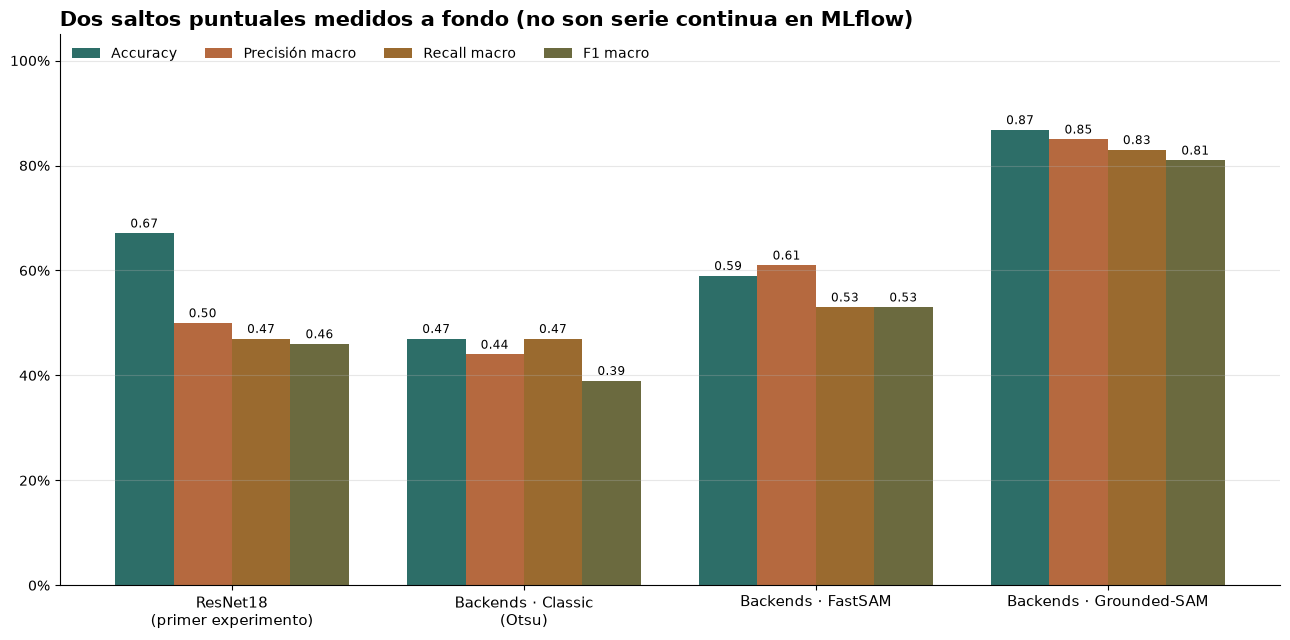

In [10]:
metrics_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
metric_labels = ["Accuracy", "Precisión macro", "Recall macro", "F1 macro"]
colors = ["#2d6e68", "#b5693f", "#9a6a2f", "#6b6a3f"]

fig, ax = plt.subplots(figsize=(13, 6.5))
n_groups = len(dd)
n_metrics = len(metrics_cols)
bar_w = 0.2
x = range(n_groups)

for i, (col, lab, c) in enumerate(zip(metrics_cols, metric_labels, colors)):
    offs = [xi + (i - n_metrics / 2 + 0.5) * bar_w for xi in x]
    bars = ax.bar(offs, dd[col], width=bar_w, label=lab, color=c)
    ax.bar_label(bars, fmt="%.2f", fontsize=8.5, padding=2)

ax.set_xticks(list(x))
ax.set_xticklabels(dd["label"], fontsize=10.5)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title("Dos saltos puntuales medidos a fondo (no son serie continua en MLflow)",
             fontsize=15, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=10, ncol=4, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "02_precision_recall_f1.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 3 — hoy: sintético + real vs. solo fotos reales, por grupo óseo

Recall por grupo, mismo examen de 83 fotos, mismo split y semillas.

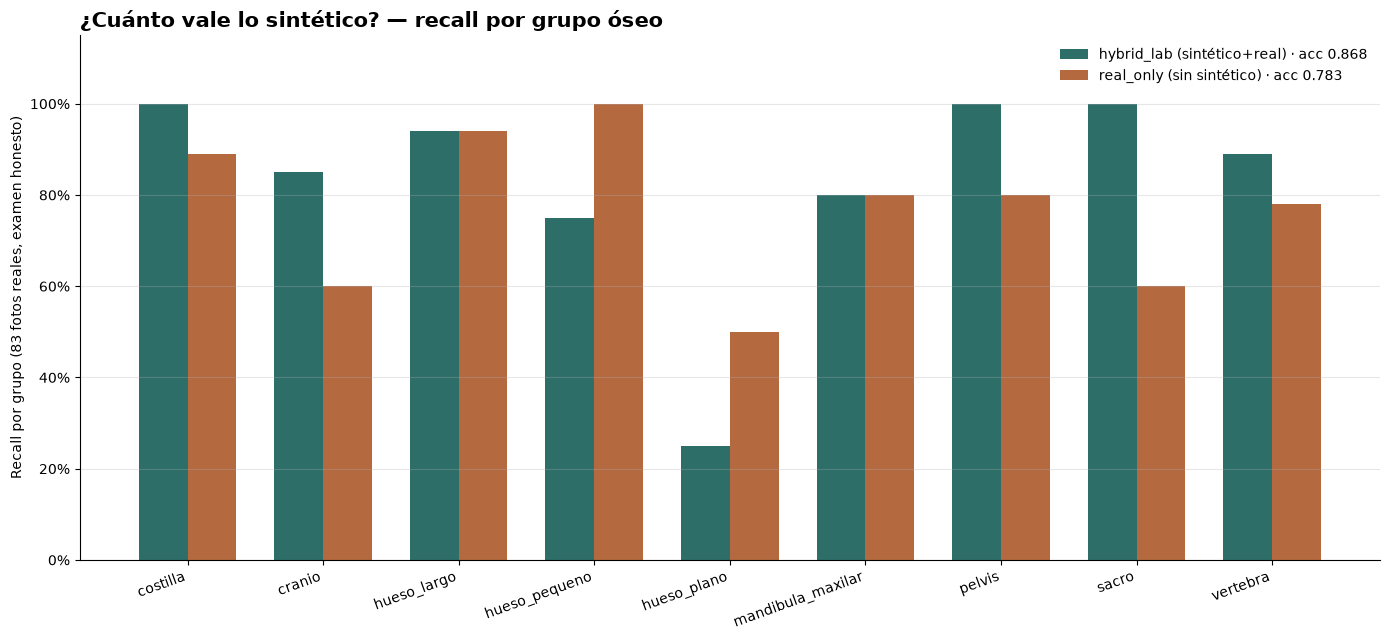

In [11]:
ab_full = df.set_index("run_name").loc[
    ["pycon26-ab-sintetico-mas-real-hybrid-lab", "pycon26-ab-sintetico-mas-real-real-only"]
].reset_index()

grupos = ["costilla", "cranio", "hueso_largo", "hueso_pequeno", "hueso_plano",
          "mandibula_maxilar", "pelvis", "sacro", "vertebra"]
recall_cols = [f"recall_{g}" for g in grupos]

hybrid_lab_row = ab_full[ab_full["run_name"] == "pycon26-ab-sintetico-mas-real-hybrid-lab"].iloc[0]
real_only_row = ab_full[ab_full["run_name"] == "pycon26-ab-sintetico-mas-real-real-only"].iloc[0]

fig, ax = plt.subplots(figsize=(14, 6.5))
x = range(len(grupos))
bar_w = 0.36
ax.bar([xi - bar_w / 2 for xi in x], [hybrid_lab_row[c] for c in recall_cols],
       width=bar_w, label=f"hybrid_lab (sintético+real) · acc {hybrid_lab_row['accuracy']:.3f}",
       color="#2d6e68")
ax.bar([xi + bar_w / 2 for xi in x], [real_only_row[c] for c in recall_cols],
       width=bar_w, label=f"real_only (sin sintético) · acc {real_only_row['accuracy']:.3f}",
       color="#b5693f")

ax.set_xticks(list(x))
ax.set_xticklabels(grupos, rotation=20, ha="right", fontsize=10)
ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_ylabel("Recall por grupo (83 fotos reales, examen honesto)")
ax.set_title("¿Cuánto vale lo sintético? — recall por grupo óseo", fontsize=15, fontweight="bold", loc="left")
ax.legend(loc="upper right", fontsize=10, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "03_ab_sintetico_vs_real.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 4 — reevaluado HOY con métricas completas (lo que sí se puede repetir)

La pregunta era: ¿se pueden repetir todos los experimentos midiendo todas las métricas?
**Parcialmente.** Reentrenar los hitos más antiguos (geométrico, cascada, primer Grounded-SAM)
no es honesto: ese código y esos datasets cambiaron o se sobrescribieron hace meses, parte vivía
en otro repo. Pero **10 checkpoints siguen en disco** (`models/cnn_model_*.pt`) — se pueden
re-evaluar ahora mismo con `evaluate_cnn_real_photos.py`, que ya calcula el `classification_report`
completo (precision/recall/F1 por clase y macro), no solo accuracy.

Resultado: una línea **de verdad continua y 100% comparable** — los 10 puntos están medidos
HOY, sobre el MISMO examen de 83 fotos, con el MISMO script. A diferencia del resto del
histórico (que mezclaba bancos de 54/72/77/83 fotos de distintas sesiones), aquí no hay
ningún "quizá no es comparable" — es la comparación más limpia de toda la charla.

In [12]:
import json

reeval = json.load(open("/tmp/claude-0/-root-dev-osteolab-ml-platform/4952efa4-7606-4057-90ab-fe4d76a28420/scratchpad/reeval_parsed.json"))

order = ["hybrid_pre_lab", "hybrid_old_seed1", "hybrid_old_seed7", "hybrid_blackbg",
         "gated_hybrid", "hybrid_lab", "hybrid_lab_seed1", "hybrid_lab_seed7", "real_only"]
labels = ["hybrid\n(pre-lab, sampler+\nmulti-instancia)", "hybrid\n(pre-lab, seed1)",
          "hybrid\n(pre-lab, seed7)", "hybrid_blackbg", "gated_hybrid\n(descartado)",
          "hybrid_lab\n(seed42, producción)", "hybrid_lab\n(seed1)", "hybrid_lab\n(seed7)",
          "real_only\n(hoy, sin sintético)"]

rows = [reeval[n] for n in order]
rdf = pd.DataFrame(rows, index=order)
rdf["label"] = labels
rdf

,accuracy,balanced_accuracy,top3_accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,label
hybrid_pre_lab,0.8434,0.7975,0.9759,0.83,0.80,0.78,0.87,0.84,0.84,"hybrid\n(pre-lab, sampler+\nmulti-instancia)"
hybrid_old_seed1,0.8554,0.7917,0.9759,0.84,0.79,0.79,0.87,0.86,0.85,"hybrid\n(pre-lab, seed1)"
hybrid_old_seed7,0.8434,0.7975,0.9518,0.83,0.80,0.78,0.86,0.84,0.84,"hybrid\n(pre-lab, seed7)"
hybrid_blackbg,0.8434,0.8043,0.9880,0.83,0.80,0.79,0.87,0.84,0.84,hybrid_blackbg
gated_hybrid,0.7831,0.7685,0.9398,0.77,0.77,0.75,0.83,0.78,0.79,gated_hybrid\n(descartado)
hybrid_lab,0.8675,0.8315,0.9759,0.85,0.83,0.81,0.89,0.87,0.86,"hybrid_lab\n(seed42, producción)"
hybrid_lab_seed1,0.8313,0.8219,1.0000,0.81,0.82,0.80,0.87,0.83,0.83,hybrid_lab\n(seed1)
hybrid_lab_seed7,0.8795,0.8210,0.9759,0.86,0.82,0.81,0.90,0.88,0.87,hybrid_lab\n(seed7)
real_only,0.7831,0.7679,0.9639,0.79,0.77,0.75,0.84,0.78,0.79,"real_only\n(hoy, sin sintético)"


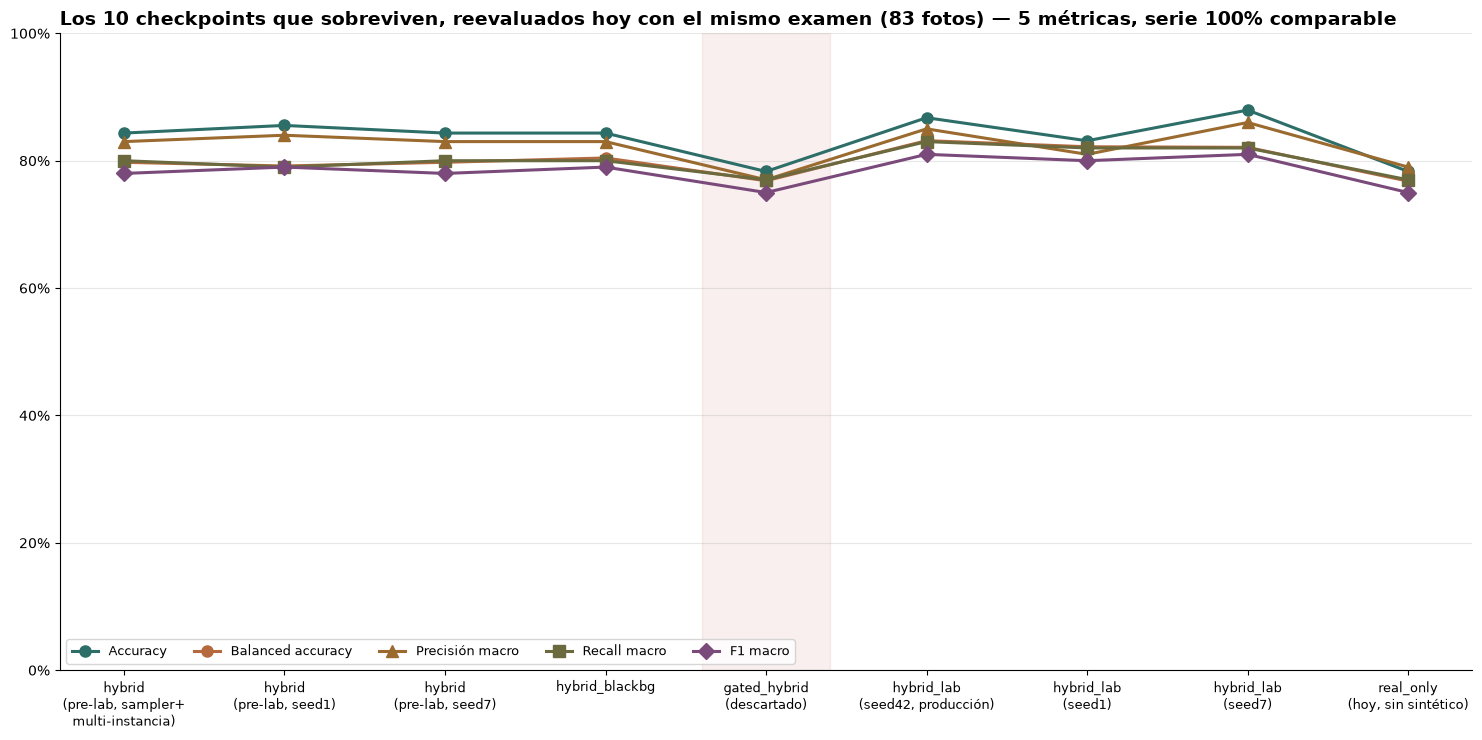

In [13]:
fig, ax = plt.subplots(figsize=(15, 7.5))
x = list(range(len(rdf)))

series = [
    ("accuracy", "Accuracy", "#2d6e68", "o"),
    ("balanced_accuracy", "Balanced accuracy", "#b5693f", "o"),
    ("precision_macro", "Precisión macro", "#9a6a2f", "^"),
    ("recall_macro", "Recall macro", "#6b6a3f", "s"),
    ("f1_macro", "F1 macro", "#7a4a7a", "D"),
]
for col, label, color, marker in series:
    ax.plot(x, rdf[col], marker=marker, markersize=8, linewidth=2.2, color=color, label=label)

descartado_idx = labels.index("gated_hybrid\n(descartado)")
ax.axvspan(descartado_idx - 0.4, descartado_idx + 0.4, color="#b23a2e", alpha=0.08, zorder=0)

ax.set_xticks(x)
ax.set_xticklabels(rdf["label"], fontsize=9.3)
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title(
    "Los 10 checkpoints que sobreviven, reevaluados hoy con el mismo examen (83 fotos) — "
    "5 métricas, serie 100% comparable",
    fontsize=13.5, fontweight="bold", loc="left"
)
ax.legend(loc="lower left", fontsize=9.5, frameon=True, ncol=5)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "04_reevaluado_hoy_completo.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 5 — qué hace DVC en este proyecto (datos reales, no inventados)

Inspeccionado directamente del repo: `.dvc` files, `git log` de cada uno, `dvc status`,
`dvc.yaml`/`params.yaml` y el tamaño real del remote (`/root/dvc-storage`). Dos cosas separadas
que DVC hace aquí:

1. **Versiona carpetas de datos pesadas** que `.gitignore` excluye de git (fotos reales
   curadas, recortes segmentados) — un único `md5` por carpeta apunta al remote local.
2. **Pipeline reproducible** (`dvc.yaml` + `params.yaml`): el entrenamiento geométrico declara
   sus dependencias y parámetros, así que `dvc repro` sabe qué volver a correr si cambia el
   dataset o un hiperparámetro.

Y una cosa que NO hace (todavía): las 4 carpetas llevan **un solo commit** desde 2026-08-13
— `dvc status` confirma que 3 de las 4 ya tienen más ficheros en disco que el último
`dvc push`. Eso es deriva real, no un adorno de la gráfica.

In [14]:
import subprocess

folders = ["real_photos_review", "segmented_crops", "real_photos_accepted", "real_world_benchmark"]

tracked = {
    "real_photos_review": 865, "segmented_crops": 4758,
    "real_photos_accepted": 397, "real_world_benchmark": 58,
}
tracked_mb = {
    "real_photos_review": 317357766 / 1e6, "segmented_crops": 215203193 / 1e6,
    "real_photos_accepted": 97722760 / 1e6, "real_world_benchmark": 95498667 / 1e6,
}
current = {}
for f in folders:
    out = subprocess.run(["find", f"../data/{f}", "-type", "f"], capture_output=True, text=True)
    current[f] = len(out.stdout.strip().splitlines())

dvc_df = pd.DataFrame({
    "carpeta": folders,
    "trackeado_en_dvc": [tracked[f] for f in folders],
    "en_disco_hoy": [current[f] for f in folders],
    "tamaño_mb_trackeado": [round(tracked_mb[f], 1) for f in folders],
})
dvc_df["deriva"] = dvc_df["en_disco_hoy"] - dvc_df["trackeado_en_dvc"]
dvc_df

,carpeta,trackeado_en_dvc,en_disco_hoy,tamaño_mb_trackeado,deriva
0,real_photos_review,865,857,317.4,-8
1,segmented_crops,4758,5944,215.2,1186
2,real_photos_accepted,397,444,97.7,47
3,real_world_benchmark,58,58,95.5,0


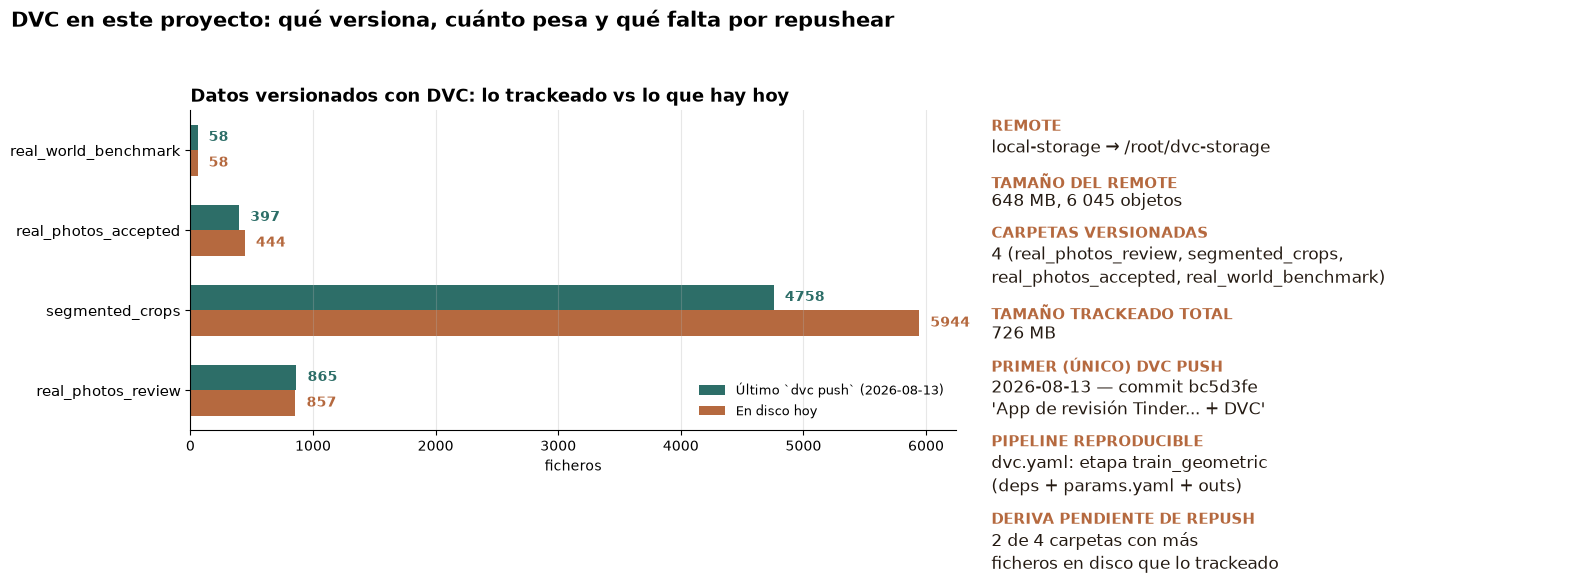

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

# -- panel izquierdo: trackeado vs en disco hoy, por carpeta --
y = range(len(dvc_df))
bar_h = 0.32
ax1.barh([yi + bar_h/2 for yi in y], dvc_df["trackeado_en_dvc"], height=bar_h,
         color="#2d6e68", label="Último `dvc push` (2026-08-13)")
ax1.barh([yi - bar_h/2 for yi in y], dvc_df["en_disco_hoy"], height=bar_h,
         color="#b5693f", label="En disco hoy")
for yi, (t, c) in enumerate(zip(dvc_df["trackeado_en_dvc"], dvc_df["en_disco_hoy"])):
    ax1.annotate(f"{t}", (t, yi + bar_h/2), textcoords="offset points", xytext=(8, 0),
                 va="center", fontsize=10, fontweight="bold", color="#2d6e68")
    ax1.annotate(f"{c}", (c, yi - bar_h/2), textcoords="offset points", xytext=(8, 0),
                 va="center", fontsize=10, fontweight="bold", color="#b5693f")
ax1.set_yticks(list(y))
ax1.set_yticklabels(dvc_df["carpeta"], fontsize=11)
ax1.set_xlabel("ficheros")
ax1.set_title("Datos versionados con DVC: lo trackeado vs lo que hay hoy", fontsize=13,
              fontweight="bold", loc="left")
ax1.legend(loc="lower right", fontsize=9.5, frameon=False)
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="x", alpha=0.3)

# -- panel derecho: resumen de infraestructura --
ax2.axis("off")
summary_lines = [
    ("Remote", "local-storage → /root/dvc-storage"),
    ("Tamaño del remote", "648 MB, 6 045 objetos"),
    ("Carpetas versionadas", "4 (real_photos_review, segmented_crops,\nreal_photos_accepted, real_world_benchmark)"),
    ("Tamaño trackeado total", f"{dvc_df['tamaño_mb_trackeado'].sum():.0f} MB"),
    ("Primer (único) dvc push", "2026-08-13 — commit bc5d3fe\n'App de revisión Tinder... + DVC'"),
    ("Pipeline reproducible", "dvc.yaml: etapa train_geometric\n(deps + params.yaml + outs)"),
    ("Deriva pendiente de repush", f"{(dvc_df['deriva'] > 0).sum()} de 4 carpetas con más\nficheros en disco que lo trackeado"),
]
y0 = 0.97
for label, value in summary_lines:
    n_lines = value.count("\n") + 1
    ax2.text(0.0, y0, label.upper(), fontsize=10.5, fontweight="bold", color="#b5693f",
              transform=ax2.transAxes, va="top")
    ax2.text(0.0, y0 - 0.052, value, fontsize=12, color="#241a12",
              transform=ax2.transAxes, va="top", linespacing=1.4)
    y0 -= 0.052 + n_lines * 0.075 + 0.04

fig.suptitle("DVC en este proyecto: qué versiona, cuánto pesa y qué falta por repushear",
             fontsize=15, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(OUT_DIR / "05_dvc_resumen.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 6 — solo los hitos con las 5 métricas completas

Filtro directo sobre el dataframe de MLflow: ningún hito elegido a mano, solo
`accuracy`, `balanced_accuracy`, `precision_macro`, `recall_macro` y `f1_macro` no nulos
a la vez. El resultado son los 10 checkpoints reevaluados hoy (mismo examen de 83 fotos)
más el A/B de real_only — el único tramo del proyecto con medición 100% completa y
100% comparable entre sí.

In [16]:
required = ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro"]
complete = df[df[required].notna().all(axis=1)].copy()
complete = complete.sort_values("start_time").reset_index(drop=True)
complete["short_name"] = complete["run_name"].str.replace("pycon26-reeval-", "", regex=False).str.replace("pycon26-", "", regex=False)
print(f"{len(complete)} de {len(df)} runs tienen las 5 métricas a la vez")
complete[["short_name", "fecha_sesion"] + required]

23 de 91 runs tienen las 5 métricas a la vez


,short_name,fecha_sesion,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,hybrid_old_seed1,2026-08-03,0.855400,0.791700,0.840000,0.790000,0.790000
1,hybrid_old_seed7,2026-08-03,0.843400,0.797500,0.830000,0.800000,0.780000
2,hybrid_pre_lab,2026-08-03,0.843400,0.797500,0.830000,0.800000,0.780000
3,reconstruido_sampler,2026-08-03,0.777778,0.715256,0.655310,0.715256,0.675847
4,reconstruido_multi_instancia,2026-08-03,0.883117,0.845767,0.875689,0.845767,0.844626
5,gated_hybrid,2026-08-13,0.783100,0.768500,0.770000,0.770000,0.750000
6,hybrid_blackbg,2026-08-13,0.843400,0.804300,0.830000,0.800000,0.790000
7,hybrid_lab,2026-08-13,0.867500,0.831500,0.850000,0.830000,0.810000
8,hybrid_lab_seed1,2026-08-13,0.831300,0.821900,0.810000,0.820000,0.800000
9,hybrid_lab_seed7,2026-08-13,0.879500,0.821000,0.860000,0.820000,0.810000


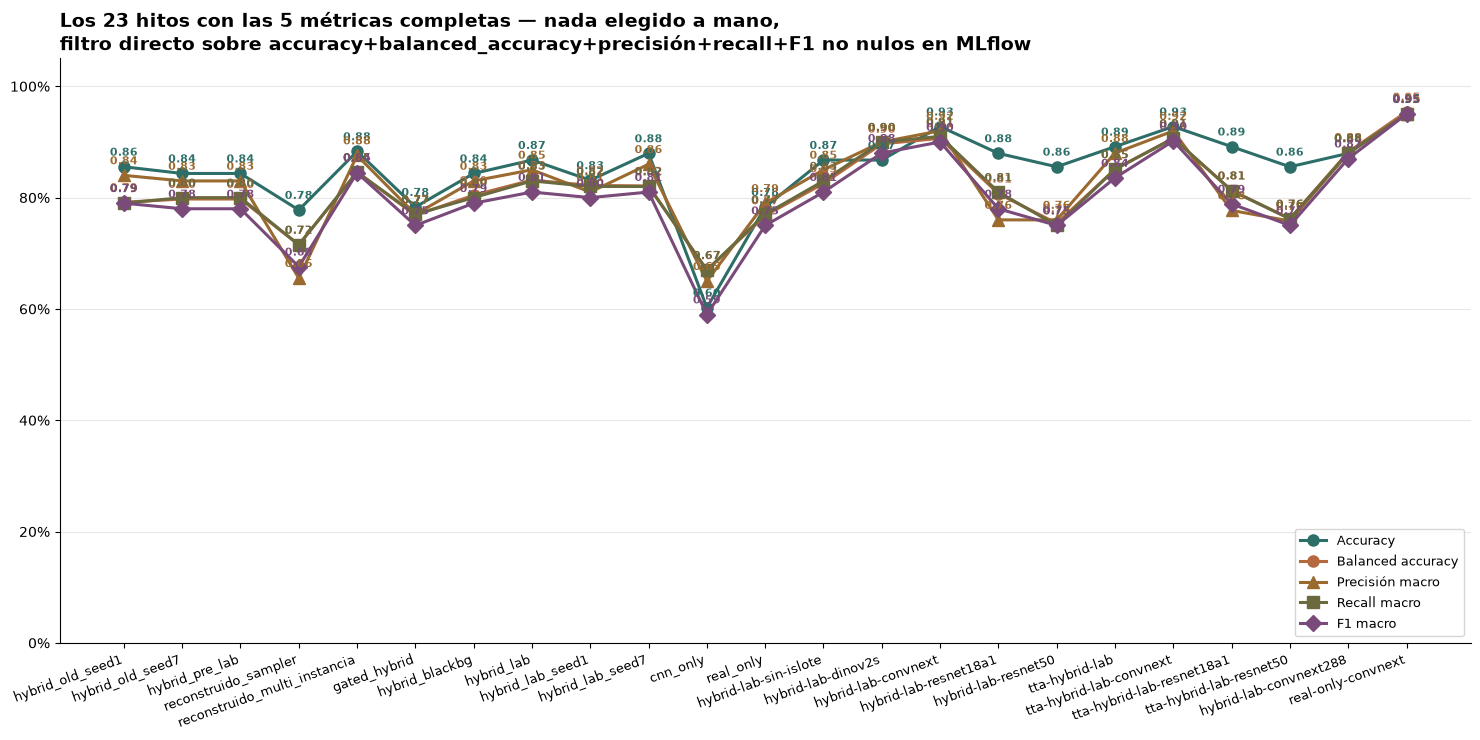

In [17]:
fig, ax = plt.subplots(figsize=(15, 7.5))
x = list(range(len(complete)))

series = [
    ("accuracy", "Accuracy", "#2d6e68", "o"),
    ("balanced_accuracy", "Balanced accuracy", "#b5693f", "o"),
    ("precision_macro", "Precisión macro", "#9a6a2f", "^"),
    ("recall_macro", "Recall macro", "#6b6a3f", "s"),
    ("f1_macro", "F1 macro", "#7a4a7a", "D"),
]
for col, label, color, marker in series:
    ax.plot(x, complete[col], marker=marker, markersize=8, linewidth=2.2, color=color, label=label)
    for xi, yi in zip(x, complete[col]):
        ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=7.6, color=color, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(complete["short_name"], fontsize=9, rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title(
    f"Los {len(complete)} hitos con las 5 métricas completas — nada elegido a mano,\n"
    "filtro directo sobre accuracy+balanced_accuracy+precisión+recall+F1 no nulos en MLflow",
    fontsize=13.5, fontweight="bold", loc="left"
)
ax.legend(loc="lower right", fontsize=9.5, frameon=True)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "06_solo_metricas_completas.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 7 — matriz de confusión, hybrid_lab en producción

El mejor checkpoint medido hoy: `hybrid_lab` (model_seed=42), examen honesto de 83 fotos
reales nunca vistas (`--source accepted --split test`). Accuracy 0.8675, balanced 0.8315.
Matriz tomada directamente de la salida de `evaluate_cnn_real_photos.py` para este run
(filas = clase real, columnas = predicción).

In [18]:
import numpy as np

classes = ["costilla", "cranio", "hueso_largo", "hueso_pequeno", "hueso_plano",
           "mandibula_maxilar", "pelvis", "sacro", "vertebra"]

# matriz tal cual la imprimio evaluate_cnn_real_photos.py --model-type hybrid --run-name hybrid_lab
# --source accepted --split test (83 fotos, accuracy 0.8675, balanced 0.8315)
cm = np.array([
    [9,  0,  0, 0, 0, 0, 0, 0, 0],
    [0, 17,  0, 1, 0, 1, 1, 0, 0],
    [1,  0, 17, 0, 0, 0, 0, 0, 0],
    [0,  0,  0, 6, 0, 0, 0, 0, 2],
    [0,  0,  0, 0, 1, 2, 0, 1, 0],
    [1,  0,  0, 0, 0, 4, 0, 0, 0],
    [0,  0,  0, 0, 0, 0, 5, 0, 0],
    [0,  0,  0, 0, 0, 0, 0, 5, 0],
    [0,  1,  0, 0, 0, 0, 0, 0, 8],
])
support = cm.sum(axis=1)
recall_per_class = cm.diagonal() / support

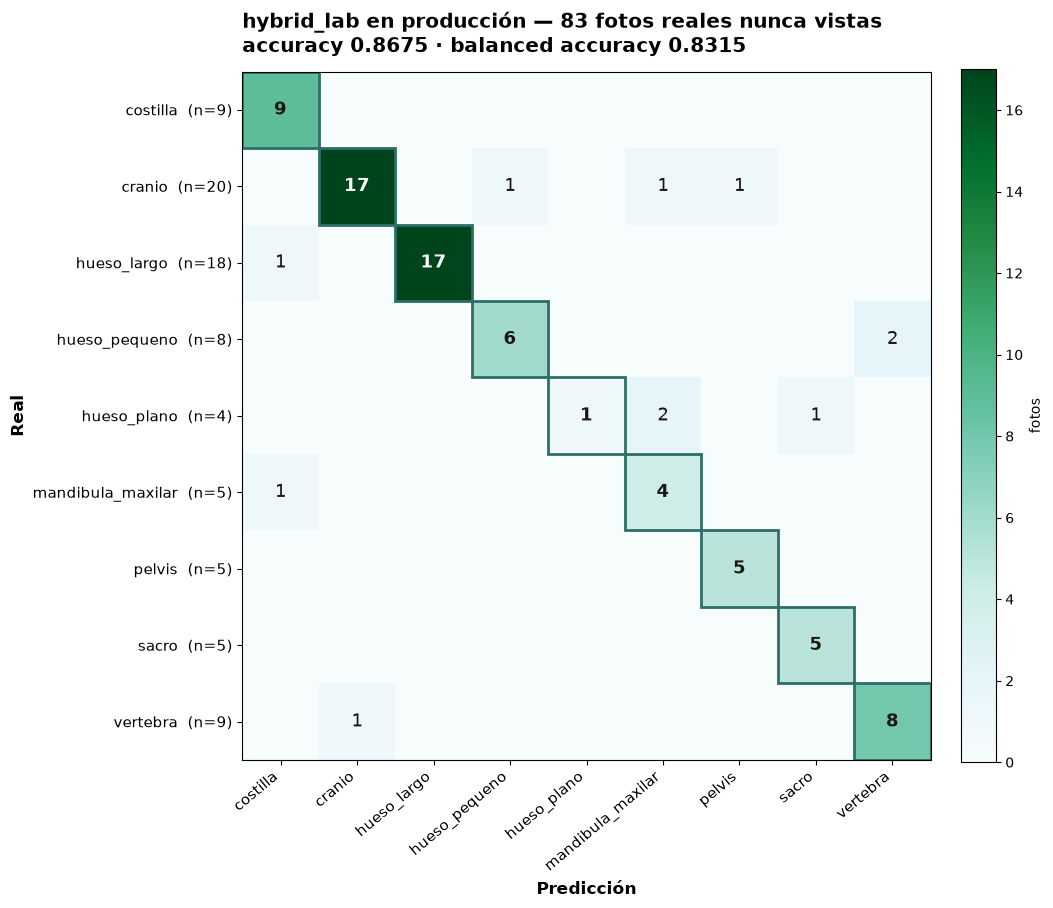

In [19]:
fig, ax = plt.subplots(figsize=(10.5, 9.5))

im = ax.imshow(cm, cmap="BuGn", vmin=0, vmax=cm.max())

for i in range(len(classes)):
    for j in range(len(classes)):
        v = cm[i, j]
        if v == 0:
            continue
        color = "white" if v > cm.max() * 0.55 else "#1c1510"
        weight = "bold" if i == j else "normal"
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color=color, fontweight=weight)

ax.set_xticks(range(len(classes)))
ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=40, ha="right", fontsize=10.5)
ax.set_yticklabels([f"{c}  (n={s})" for c, s in zip(classes, support)], fontsize=10.5)
ax.set_xlabel("Predicción", fontsize=12, fontweight="bold")
ax.set_ylabel("Real", fontsize=12, fontweight="bold")
ax.set_title(
    "hybrid_lab en producción — 83 fotos reales nunca vistas\n"
    "accuracy 0.8675 · balanced accuracy 0.8315",
    fontsize=14.5, fontweight="bold", loc="left", pad=14
)

# marca la diagonal
for i in range(len(classes)):
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#2d6e68", linewidth=2))

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("fotos", fontsize=10)

fig.tight_layout()
fig.savefig(OUT_DIR / "07_matriz_confusion_hybrid_lab.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 8 — tablas de métricas, hybrid_lab en producción

Las mismas cifras de la matriz de confusión (Gráfica 7), en tabla: globales
(normales + balanceadas) y por grupo óseo. Exportadas como PNG para descargar.

In [20]:
globales = pd.DataFrame({
    "Métrica": ["Accuracy", "Balanced accuracy", "Precisión macro", "Recall macro", "F1 macro",
                "Precisión weighted", "Recall weighted", "F1 weighted", "Top-3 accuracy"],
    "Valor": [0.8675, 0.8315, 0.85, 0.83, 0.81, 0.89, 0.87, 0.86, 0.9759],
})

por_grupo = pd.DataFrame({
    "Grupo": ["costilla", "cráneo", "hueso_largo", "hueso_pequeño", "hueso_plano",
              "mandíbula_maxilar", "pelvis", "sacro", "vértebra"],
    "Precisión": [0.82, 0.94, 1.00, 0.86, 1.00, 0.57, 0.83, 0.83, 0.80],
    "Recall": [1.00, 0.85, 0.94, 0.75, 0.25, 0.80, 1.00, 1.00, 0.89],
    "F1": [0.90, 0.89, 0.97, 0.80, 0.40, 0.67, 0.91, 0.91, 0.84],
    "n": [9, 20, 18, 8, 4, 5, 5, 5, 9],
})

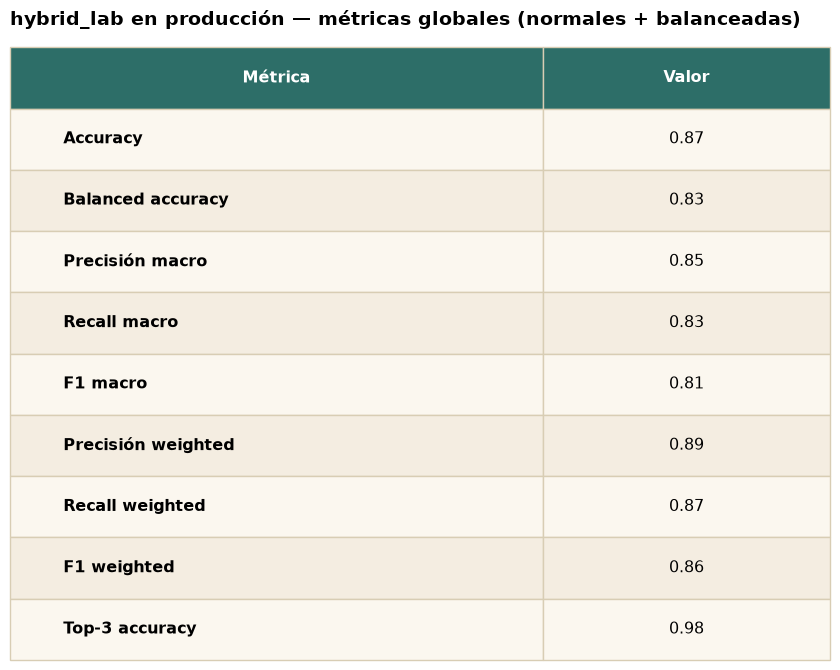

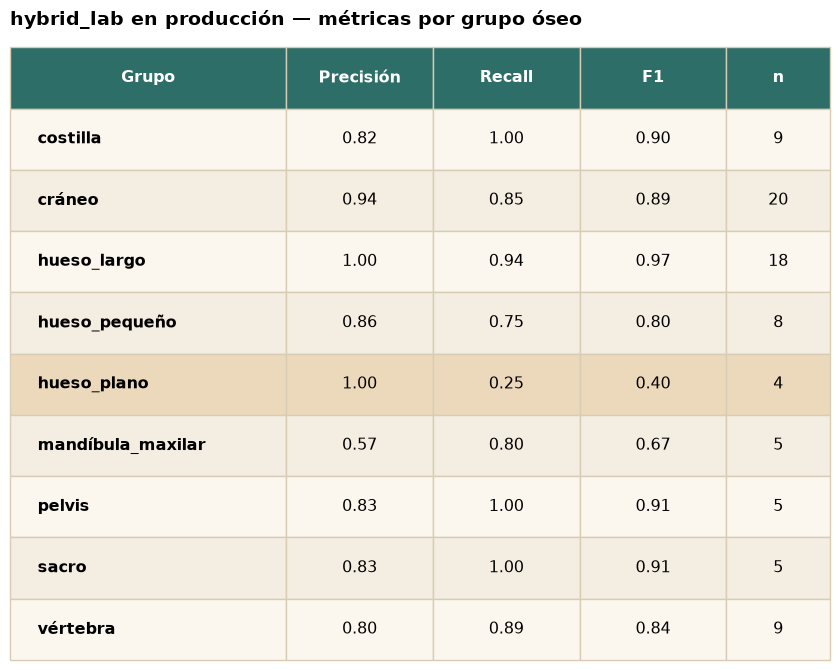

In [21]:
def df_to_png(df, title, path, col_widths=None, highlight_row=None):
    n_rows, n_cols = df.shape
    fig_h = 0.62 * (n_rows + 1) + 0.6
    fig, ax = plt.subplots(figsize=(8.5, fig_h))
    ax.axis("off")
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left", pad=16)

    cell_text = []
    for _, row in df.iterrows():
        vals = []
        for c in df.columns:
            v = row[c]
            vals.append(f"{v:.2f}" if isinstance(v, float) else str(v))
        cell_text.append(vals)

    table = ax.table(cellText=cell_text, colLabels=df.columns, cellLoc="center",
                      bbox=[0, 0, 1, 1], colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(11.5)
    table.scale(1, 1.9)

    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor("#d8cdb4")
        if r == 0:
            cell.set_facecolor("#2d6e68")
            cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor("#fbf7ef" if r % 2 else "#f4ede1")
            if c == 0:
                cell.set_text_props(ha="left", fontweight="bold")
            if highlight_row is not None and r - 1 == highlight_row:
                cell.set_facecolor("#ecd9bc")

    fig.tight_layout()
    fig.savefig(path, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()

df_to_png(globales, "hybrid_lab en producción — métricas globales (normales + balanceadas)",
          OUT_DIR / "08a_tabla_metricas_globales.png", col_widths=[0.65, 0.35])
df_to_png(por_grupo, "hybrid_lab en producción — métricas por grupo óseo",
          OUT_DIR / "08b_tabla_metricas_por_grupo.png", col_widths=[0.32, 0.17, 0.17, 0.17, 0.12], highlight_row=4)  # hueso_plano resaltado

## Gráfica 9 — versión sepia/pergamino, sueltas, para composición

Las mismas 4 piezas (curva de evolución, matriz de confusión, tabla por grupo, tabla de
métricas globales), en el tema sepia del resto del deck, cada una exportada por separado
con la proporción con la que se va a montar en una composición tipo póster.

In [22]:
# paleta sepia/pergamino (la misma del deck de diapositivas)
SEPIA_BG = "#fbf7ef"
SEPIA_PANEL = "#f4ede1"
SEPIA_DARK = "#241a12"
SEPIA_TEXT = "#3a2c1d"
SEPIA_MUTED = "#8a765c"
SEPIA_BORDER = "#d8cdb4"
SEPIA_ACCENT = "#b5693f"   # terracota
SEPIA_ACCENT2 = "#7a8c74"  # salvia
SEPIA_TEAL = "#2d6e68"
SEPIA_BAD = "#b23a2e"

plt.rcParams["font.family"] = "serif"

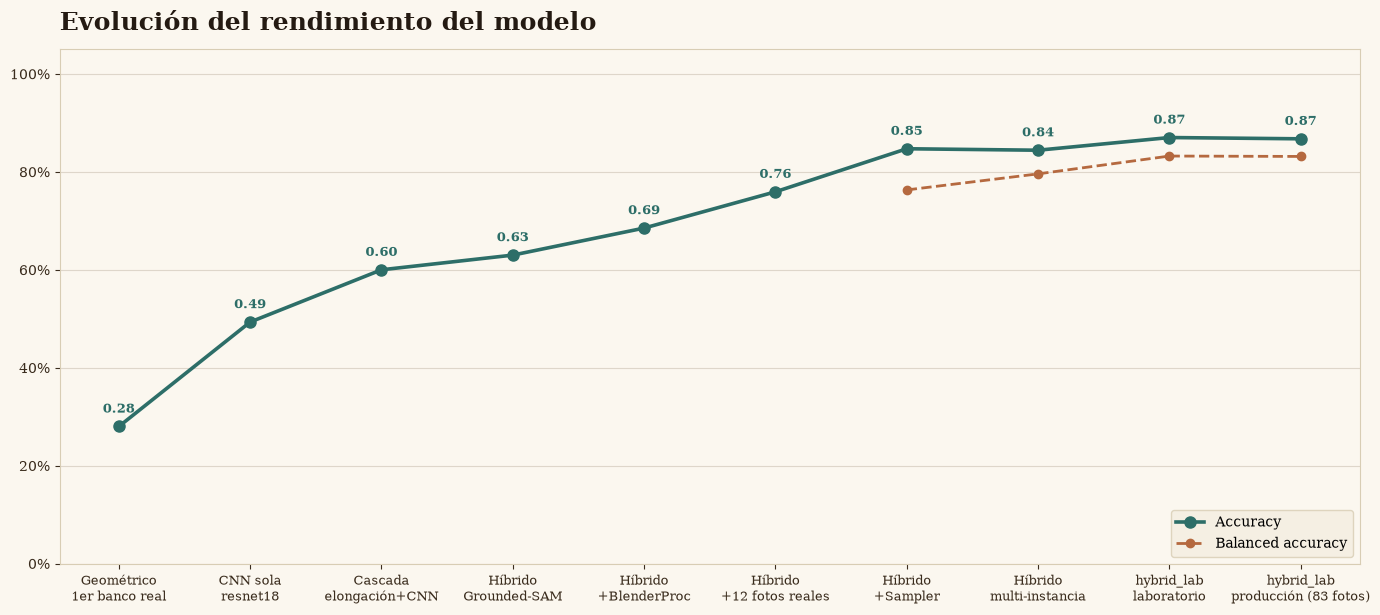

In [23]:
fig, ax = plt.subplots(figsize=(14, 6.25))
fig.patch.set_facecolor(SEPIA_BG)
ax.set_facecolor(SEPIA_BG)

x = list(range(len(spine)))
ax.plot(x, spine["accuracy"], marker="o", markersize=8, linewidth=2.6, color=SEPIA_TEAL, label="Accuracy")
for xi, yi in zip(x, spine["accuracy"]):
    ax.annotate(f"{yi:.2f}", (xi, yi), textcoords="offset points", xytext=(0, 10),
                ha="center", fontsize=9, fontweight="bold", color=SEPIA_TEAL)

bal_mask = spine["balanced_accuracy"].notna()
bal_x = [xi for xi, m in zip(x, bal_mask) if m]
bal_y = spine.loc[bal_mask, "balanced_accuracy"]
ax.plot(bal_x, bal_y, marker="o", markersize=6, linewidth=2, linestyle="--", color=SEPIA_ACCENT, label="Balanced accuracy")

ax.set_xticks(x)
ax.set_xticklabels(spine["label"], fontsize=9.5, color=SEPIA_TEXT)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.tick_params(colors=SEPIA_TEXT)
ax.set_title("Evolución del rendimiento del modelo", fontsize=18, fontweight="bold",
             color=SEPIA_DARK, loc="left", pad=14)
ax.legend(loc="lower right", fontsize=10, frameon=True, facecolor=SEPIA_PANEL, edgecolor=SEPIA_BORDER)
ax.grid(axis="y", alpha=0.25, color=SEPIA_MUTED)
for spine_ in ax.spines.values():
    spine_.set_color(SEPIA_BORDER)

fig.tight_layout()
fig.savefig(OUT_DIR / "09a_evolucion_sepia.png", dpi=200, facecolor=SEPIA_BG)
plt.show()

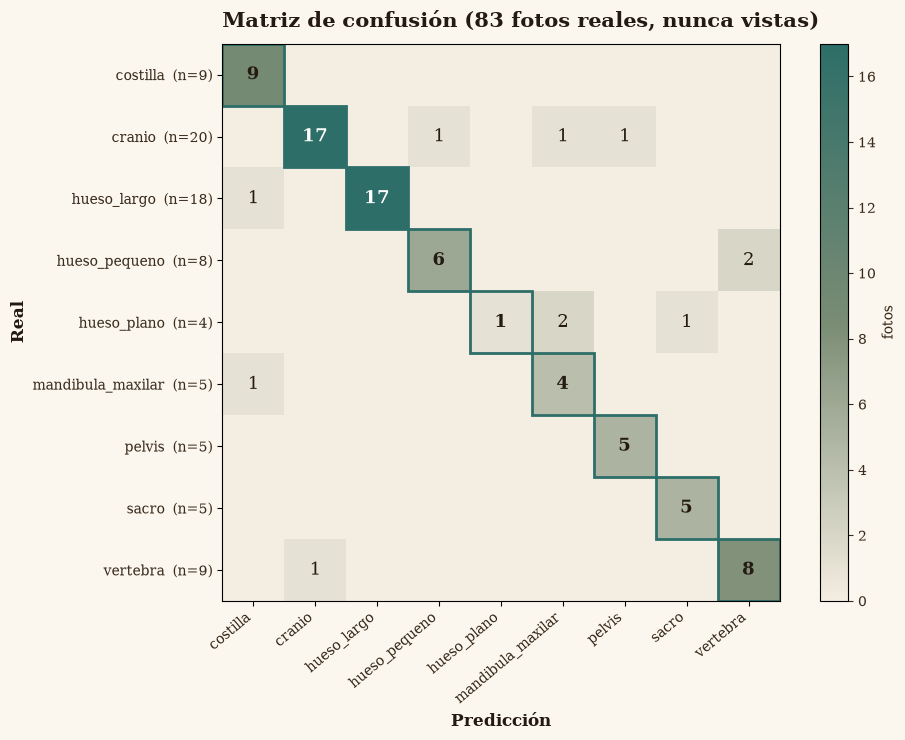

In [24]:
fig, ax = plt.subplots(figsize=(11, 7.5))
fig.patch.set_facecolor(SEPIA_BG)

from matplotlib.colors import LinearSegmentedColormap
sepia_cmap = LinearSegmentedColormap.from_list("sepia", [SEPIA_PANEL, SEPIA_ACCENT2, SEPIA_TEAL])

im = ax.imshow(cm, cmap=sepia_cmap, vmin=0, vmax=cm.max())
for i in range(len(classes)):
    for j in range(len(classes)):
        v = cm[i, j]
        if v == 0:
            continue
        color = "white" if v > cm.max() * 0.55 else SEPIA_DARK
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color=color,
                fontweight="bold" if i == j else "normal")

ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=40, ha="right", fontsize=10, color=SEPIA_TEXT)
ax.set_yticklabels([f"{c}  (n={s})" for c, s in zip(classes, support)], fontsize=10, color=SEPIA_TEXT)
ax.set_xlabel("Predicción", fontsize=12, fontweight="bold", color=SEPIA_DARK)
ax.set_ylabel("Real", fontsize=12, fontweight="bold", color=SEPIA_DARK)
ax.set_title("Matriz de confusión (83 fotos reales, nunca vistas)", fontsize=15,
             fontweight="bold", color=SEPIA_DARK, loc="left", pad=12)
for i in range(len(classes)):
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=SEPIA_TEAL, linewidth=2))
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("fotos", fontsize=10, color=SEPIA_TEXT)
cbar.ax.yaxis.set_tick_params(color=SEPIA_TEXT)
plt.setp(cbar.ax.get_yticklabels(), color=SEPIA_TEXT)

fig.tight_layout()
fig.savefig(OUT_DIR / "09b_matriz_confusion_sepia.png", dpi=200, facecolor=SEPIA_BG)
plt.show()

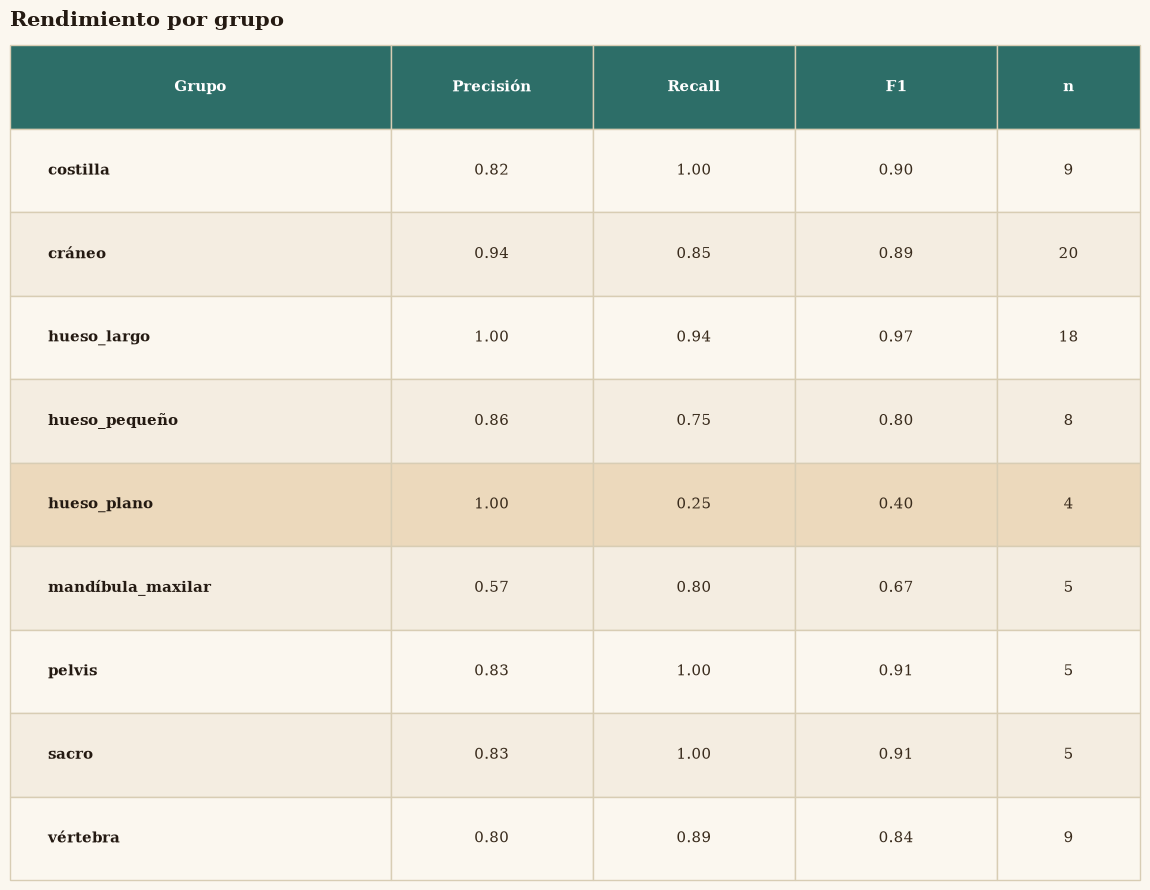

In [25]:
def df_to_png_sepia(df, title, path, figsize, col_widths=None, highlight_row=None, highlight_cols=None):
    fig, ax = plt.subplots(figsize=figsize)
    fig.patch.set_facecolor(SEPIA_BG)
    ax.axis("off")
    ax.set_title(title, fontsize=15, fontweight="bold", color=SEPIA_DARK, loc="left", pad=14)

    cell_text = []
    for _, row in df.iterrows():
        vals = []
        for c in df.columns:
            v = row[c]
            vals.append(f"{v:.2f}" if isinstance(v, float) else str(v))
        cell_text.append(vals)

    table = ax.table(cellText=cell_text, colLabels=df.columns, cellLoc="center",
                      bbox=[0, 0, 1, 1], colWidths=col_widths)
    table.auto_set_font_size(False)
    table.set_fontsize(11)
    table.scale(1, 1.9)

    n_rows = len(df)
    for (r, c), cell in table.get_celld().items():
        cell.set_edgecolor(SEPIA_BORDER)
        if r == 0:
            cell.set_facecolor(SEPIA_TEAL)
            cell.set_text_props(color="white", fontweight="bold")
        else:
            cell.set_facecolor(SEPIA_BG if r % 2 else SEPIA_PANEL)
            cell.set_text_props(color=SEPIA_TEXT)
            if c == 0:
                cell.set_text_props(ha="left", fontweight="bold", color=SEPIA_DARK)
            if highlight_row is not None and r - 1 == highlight_row:
                cell.set_facecolor("#ecd9bc")

    fig.tight_layout()
    fig.savefig(path, dpi=200, facecolor=SEPIA_BG, bbox_inches="tight")
    plt.show()

df_to_png_sepia(por_grupo, "Rendimiento por grupo", OUT_DIR / "09c_tabla_por_grupo_sepia.png",
                 figsize=(11.6, 9), col_widths=[0.32, 0.17, 0.17, 0.17, 0.12], highlight_row=4)

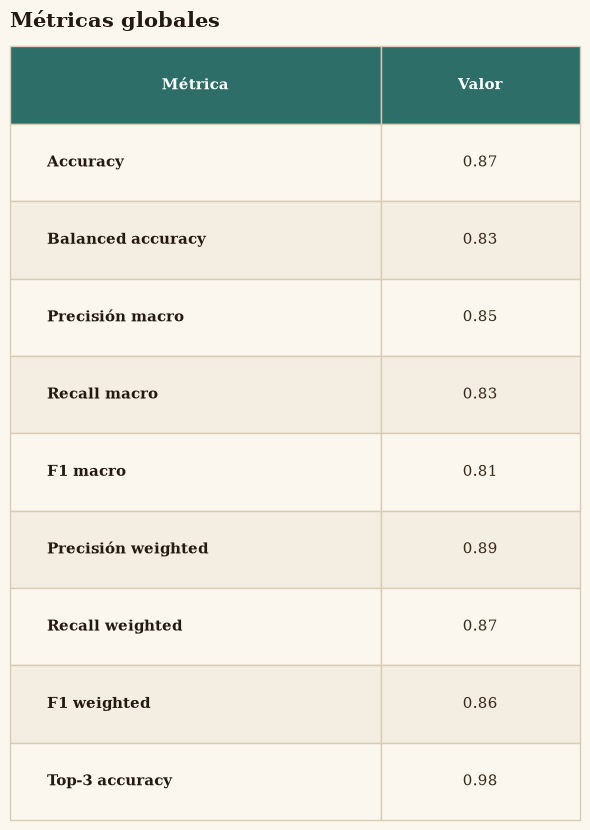

In [26]:
df_to_png_sepia(globales, "Métricas globales", OUT_DIR / "09d_tabla_globales_sepia.png",
                 figsize=(6, 8.4), col_widths=[0.65, 0.35])

## Gráfica 10 — ¿hay domain gap? Embeddings sintético vs real (UMAP)

Se extrae la penúltima capa (128-d, justo antes de la clasificación final) del
checkpoint `hybrid_lab` en producción, para una muestra equilibrada de filas sintéticas
(escena de laboratorio, ~45 por grupo) y las 349 fotos reales curadas. Se proyecta con
UMAP a 2D y se colorea por origen: si las nubes se mezclan, el modelo ha aprendido una
representación compartida (Sim2Real funciona); si quedan separadas, hay domain gap.

In [27]:
import umap

data = np.load("/tmp/claude-0/-root-dev-osteolab-ml-platform/4952efa4-7606-4057-90ab-fe4d76a28420/scratchpad/embeddings.npz", allow_pickle=True)
emb_synth, lab_synth = data["emb_synth"], data["lab_synth"]
emb_real, lab_real = data["emb_real"], data["lab_real"]
classes = data["classes"]

X = np.concatenate([emb_synth, emb_real])
origin = np.array(["Sintético"] * len(emb_synth) + ["Real"] * len(emb_real))
groups = np.concatenate([classes[lab_synth], classes[lab_real]])

reducer = umap.UMAP(n_neighbors=25, min_dist=0.3, metric="cosine", random_state=42)
proj = reducer.fit_transform(X)

print(f"{len(emb_synth)} sintéticas + {len(emb_real)} reales -> proyección UMAP {proj.shape}")

/root/dev/osteolab-ml-platform/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


405 sintéticas + 349 reales -> proyección UMAP (754, 2)


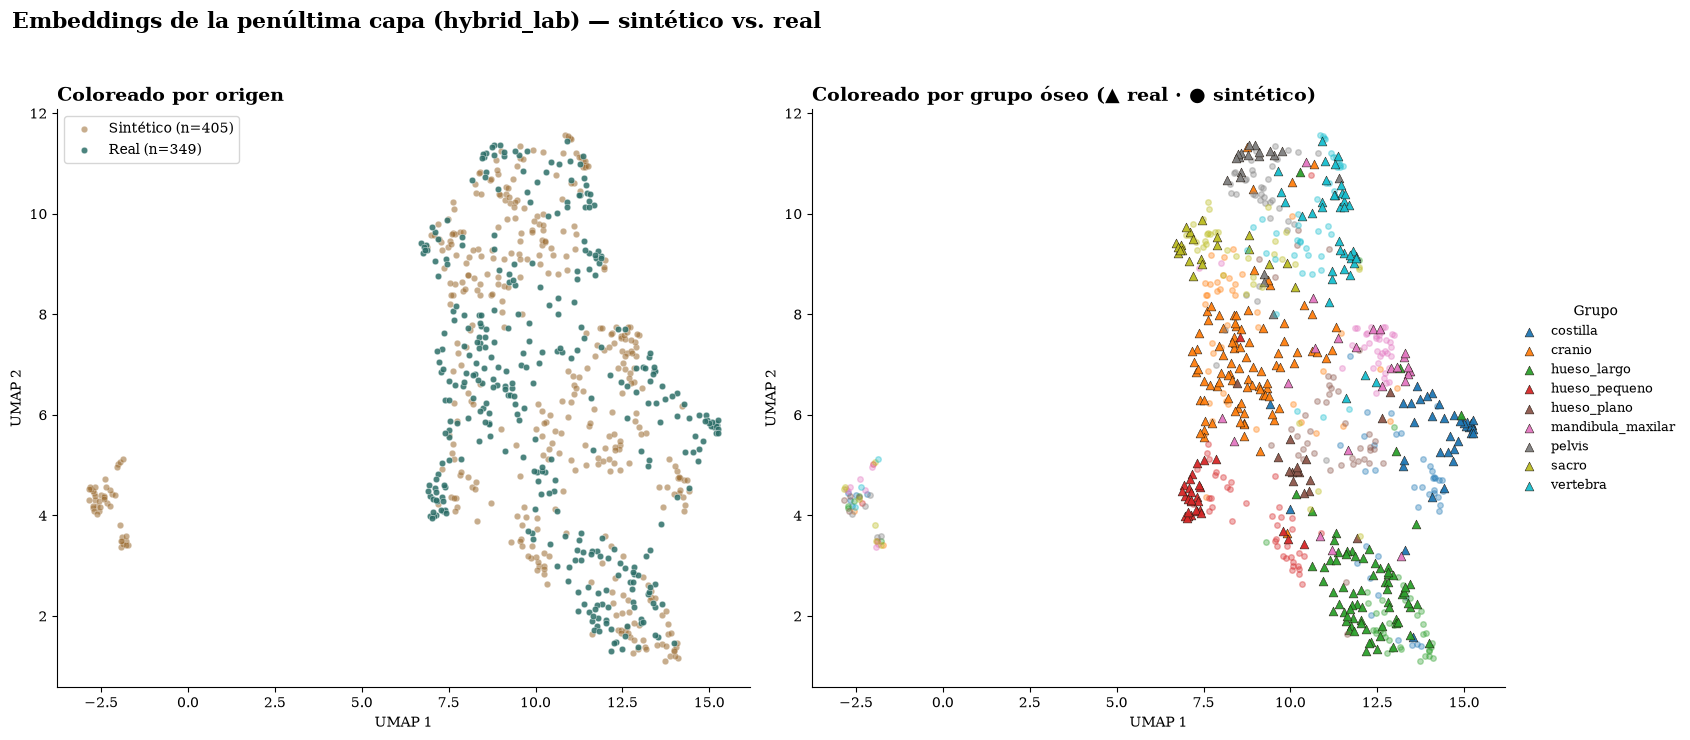

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

# -- panel 1: coloreado por origen (sintetico vs real) --
ax = axes[0]
for o, color, alpha in [("Sintético", "#9a6a2f", 0.55), ("Real", "#2d6e68", 0.85)]:
    mask = origin == o
    ax.scatter(proj[mask, 0], proj[mask, 1], s=22, color=color, alpha=alpha, label=f"{o} (n={mask.sum()})",
               edgecolor="white", linewidth=0.3)
ax.set_title("Coloreado por origen", fontsize=14, fontweight="bold", loc="left")
ax.legend(loc="best", fontsize=10, frameon=True)
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
ax.spines[["top", "right"]].set_visible(False)

# -- panel 2: coloreado por grupo oseo (misma proyeccion), real en circulo grande / sintetico en punto chico --
ax = axes[1]
palette = plt.colormaps.get_cmap("tab10").resampled(len(classes))
color_map = {c: palette(i) for i, c in enumerate(classes)}
for c in classes:
    m_synth = (groups == c) & (origin == "Sintético")
    m_real = (groups == c) & (origin == "Real")
    ax.scatter(proj[m_synth, 0], proj[m_synth, 1], s=16, color=color_map[c], alpha=0.35, marker="o")
    ax.scatter(proj[m_real, 0], proj[m_real, 1], s=40, color=color_map[c], alpha=0.95, marker="^",
               edgecolor="#241a12", linewidth=0.4, label=c)
ax.set_title("Coloreado por grupo óseo (▲ real · ● sintético)", fontsize=14, fontweight="bold", loc="left")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9, frameon=False, title="Grupo")
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Embeddings de la penúltima capa (hybrid_lab) — sintético vs. real",
             fontsize=16, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(OUT_DIR / "10_umap_domain_gap.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

## Gráfica 11 — comparación de backbones: resnet18 vs DINOv2 vs ConvNeXt

Mismo dataset (`combined_lab.csv`), mismo split, mismo seed (random_state=42,
model_seed=42), mismo examen de 83 fotos reales — solo cambia el backbone de visión
dentro del modelo híbrido. **ConvNeXt-tiny da el mejor resultado de todo el proyecto.**

In [29]:
backbone_runs = [
    "pycon26-reeval-hybrid_lab",  # resnet18, referencia (hybrid_lab producción)
    "pycon26-hybrid-lab-sin-islote",
    "pycon26-hybrid-lab-dinov2s",
    "pycon26-hybrid-lab-convnext",
]
labels_bb = ["resnet18\n(referencia)", "resnet18\nsin islote UMAP", "DINOv2 ViT-S/14", "ConvNeXt-tiny"]

dfi = df.set_index("run_name")
bb = dfi.loc[backbone_runs, ["accuracy", "balanced_accuracy", "precision_macro", "recall_macro", "f1_macro"]].reset_index()
bb["label"] = labels_bb
bb

,run_name,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,label
0,pycon26-reeval-hybrid_lab,0.8675,0.8315,0.85,0.83,0.81,resnet18\n(referencia)
1,pycon26-hybrid-lab-sin-islote,0.8675,0.8253,0.85,0.83,0.81,resnet18\nsin islote UMAP
2,pycon26-hybrid-lab-dinov2s,0.8675,0.8966,0.90,0.90,0.88,DINOv2 ViT-S/14
3,pycon26-hybrid-lab-convnext,0.9277,0.9065,0.92,0.91,0.90,ConvNeXt-tiny


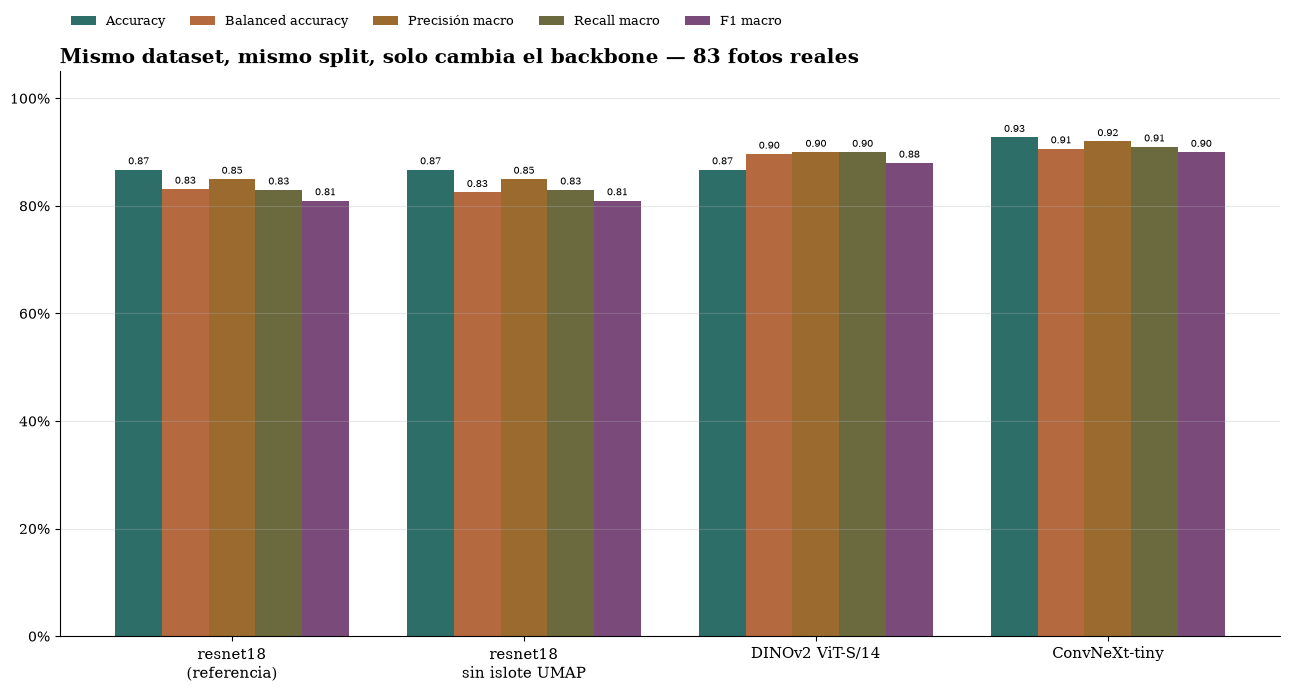

In [30]:
fig, ax = plt.subplots(figsize=(13, 7))
metrics_bb = [
    ("accuracy", "Accuracy", "#2d6e68"),
    ("balanced_accuracy", "Balanced accuracy", "#b5693f"),
    ("precision_macro", "Precisión macro", "#9a6a2f"),
    ("recall_macro", "Recall macro", "#6b6a3f"),
    ("f1_macro", "F1 macro", "#7a4a7a"),
]
x = range(len(bb))
n_m = len(metrics_bb)
bar_w = 0.16
for i, (col, label, color) in enumerate(metrics_bb):
    offs = [xi + (i - n_m / 2 + 0.5) * bar_w for xi in x]
    bars = ax.bar(offs, bb[col], width=bar_w, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", fontsize=7.5, padding=2)

ax.set_xticks(list(x))
ax.set_xticklabels(bb["label"], fontsize=11)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title("Mismo dataset, mismo split, solo cambia el backbone — 83 fotos reales",
             fontsize=14.5, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9, ncol=5, frameon=False, bbox_to_anchor=(0, 1.12))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "11_comparacion_backbones.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 12 — las 6 ideas de "menos a más esfuerzo", probadas y documentadas

Lista propuesta: (1) pesos timm modernos, (2) TTA, (3) pesos por clase en la pérdida,
(4) LR discriminativo + descongelado progresivo, (5) resolución 288px, (6) ResNet50.
**3 y 4 ya estaban implementados** en `train_cnn.py` desde antes (class_weight='balanced'
+ dos grupos de LR backbone/cabeza) — no son experimentos nuevos, son la base de todos los
runs de hoy. De las 4 restantes, **solo TTA dio mejora limpia** sin reentrenar nada.

In [31]:
ideas_runs = [
    "pycon26-reeval-hybrid_lab",             # baseline resnet18
    "pycon26-hybrid-lab-resnet18a1",         # idea 1
    "pycon26-tta-hybrid-lab",                # idea 2 (TTA sobre baseline)
    "pycon26-hybrid-lab-convnext288",        # idea 5 (sobre el mejor backbone)
    "pycon26-hybrid-lab-resnet50",           # idea 6
    "pycon26-hybrid-lab-convnext",           # mejor backbone encontrado hoy, referencia
    "pycon26-tta-hybrid-lab-convnext",       # TTA sobre el mejor
]
labels_ideas = [
    "resnet18\n(baseline)", "resnet18\n+ pesos timm a1", "resnet18\n+ TTA",
    "ConvNeXt\n288px", "resnet50", "ConvNeXt-tiny\n(mejor, 224px)", "ConvNeXt-tiny\n+ TTA",
]
dfi = df.set_index("run_name")
ideas = dfi.loc[ideas_runs, ["accuracy", "balanced_accuracy"]].reset_index()
ideas["label"] = labels_ideas
ideas

,run_name,accuracy,balanced_accuracy,label
0,pycon26-reeval-hybrid_lab,0.8675,0.8315,resnet18\n(baseline)
1,pycon26-hybrid-lab-resnet18a1,0.8795,0.8071,resnet18\n+ pesos timm a1
2,pycon26-tta-hybrid-lab,0.8916,0.8509,resnet18\n+ TTA
3,pycon26-hybrid-lab-convnext288,0.8795,0.8818,ConvNeXt\n288px
4,pycon26-hybrid-lab-resnet50,0.8554,0.7537,resnet50
5,pycon26-hybrid-lab-convnext,0.9277,0.9065,"ConvNeXt-tiny\n(mejor, 224px)"
6,pycon26-tta-hybrid-lab-convnext,0.9277,0.9065,ConvNeXt-tiny\n+ TTA


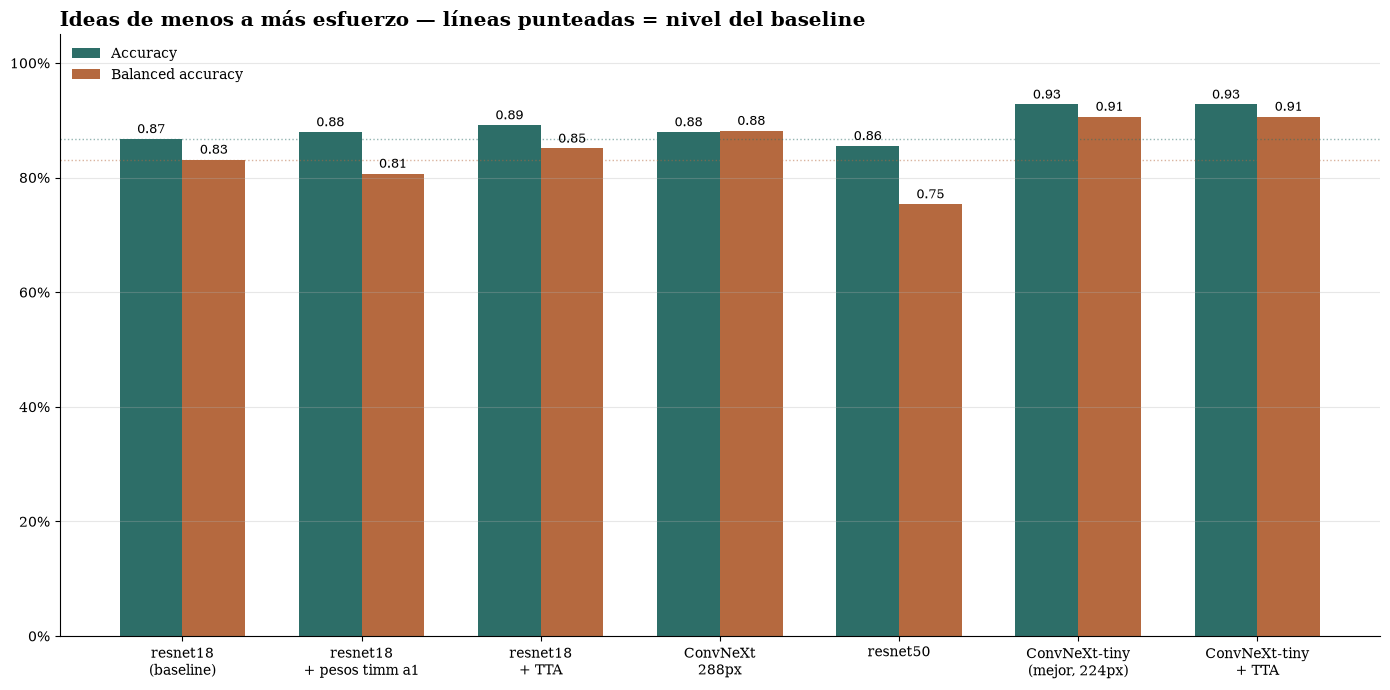

In [32]:
fig, ax = plt.subplots(figsize=(14, 7))
x = range(len(ideas))
bar_w = 0.35
bars1 = ax.bar([xi - bar_w/2 for xi in x], ideas["accuracy"], width=bar_w, color="#2d6e68", label="Accuracy")
bars2 = ax.bar([xi + bar_w/2 for xi in x], ideas["balanced_accuracy"], width=bar_w, color="#b5693f", label="Balanced accuracy")
ax.bar_label(bars1, fmt="%.2f", fontsize=9, padding=2)
ax.bar_label(bars2, fmt="%.2f", fontsize=9, padding=2)

# linea de referencia del baseline para ver de un vistazo quien mejora/empeora
ax.axhline(ideas.loc[0, "accuracy"], color="#2d6e68", linewidth=1, linestyle=":", alpha=0.5)
ax.axhline(ideas.loc[0, "balanced_accuracy"], color="#b5693f", linewidth=1, linestyle=":", alpha=0.5)

ax.set_xticks(list(x))
ax.set_xticklabels(ideas["label"], fontsize=10)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title("Ideas de menos a más esfuerzo — líneas punteadas = nivel del baseline",
             fontsize=14.5, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=10, frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "12_ideas_esfuerzo_bajo.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 13 — matriz de confusión y tabla por grupo, ConvNeXt-tiny (el mejor)

Mismo examen de 83 fotos, mismo split, mismo seed que `hybrid_lab` — solo cambia el
backbone. accuracy 0.9277, balanced accuracy 0.9065.

In [33]:
classes_cx = ["costilla", "cranio", "hueso_largo", "hueso_pequeno", "hueso_plano",
              "mandibula_maxilar", "pelvis", "sacro", "vertebra"]

cm_convnext = np.array([
    [9,  0,  0, 0, 0, 0, 0, 0, 0],
    [0, 19,  0, 0, 0, 1, 0, 0, 0],
    [0,  0, 17, 1, 0, 0, 0, 0, 0],
    [0,  0,  0, 7, 0, 0, 0, 0, 1],
    [0,  0,  1, 1, 2, 0, 0, 0, 0],
    [0,  0,  0, 0, 0, 5, 0, 0, 0],
    [0,  0,  0, 0, 0, 0, 5, 0, 0],
    [0,  0,  0, 0, 0, 0, 0, 5, 0],
    [0,  0,  0, 0, 0, 0, 1, 0, 8],
])
support_cx = cm_convnext.sum(axis=1)

por_grupo_convnext = pd.DataFrame({
    "Grupo": ["costilla", "cráneo", "hueso_largo", "hueso_pequeño", "hueso_plano",
              "mandíbula_maxilar", "pelvis", "sacro", "vértebra"],
    "Precisión": [1.00, 1.00, 0.94, 0.78, 1.00, 0.83, 0.83, 1.00, 0.89],
    "Recall":    [1.00, 0.95, 0.94, 0.88, 0.50, 1.00, 1.00, 1.00, 0.89],
    "F1":        [1.00, 0.97, 0.94, 0.82, 0.67, 0.91, 0.91, 1.00, 0.89],
    "n": support_cx.tolist(),
})
por_grupo_convnext

,Grupo,Precisión,Recall,F1,n
0,costilla,1.00,1.00,1.00,9
1,cráneo,1.00,0.95,0.97,20
2,hueso_largo,0.94,0.94,0.94,18
3,hueso_pequeño,0.78,0.88,0.82,8
4,hueso_plano,1.00,0.50,0.67,4
5,mandíbula_maxilar,0.83,1.00,0.91,5
6,pelvis,0.83,1.00,0.91,5
7,sacro,1.00,1.00,1.00,5
8,vértebra,0.89,0.89,0.89,9


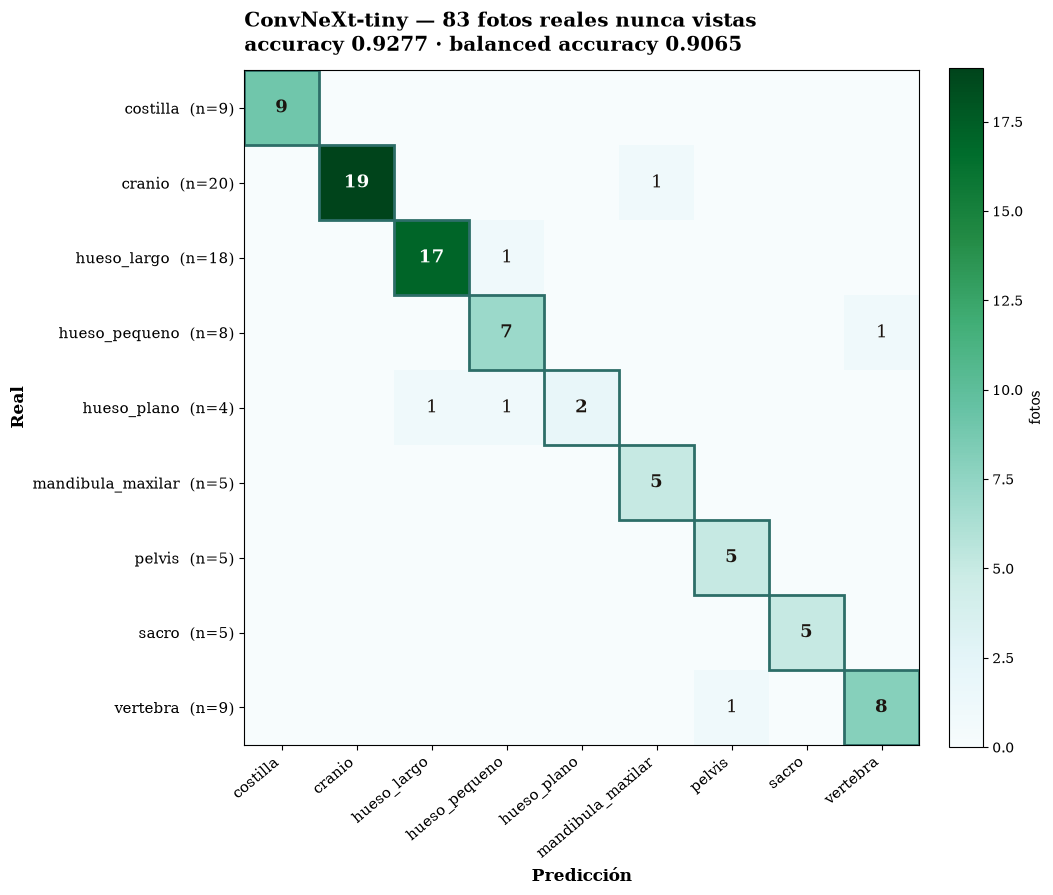

In [34]:
fig, ax = plt.subplots(figsize=(10.5, 9.5))
im = ax.imshow(cm_convnext, cmap="BuGn", vmin=0, vmax=cm_convnext.max())
for i in range(len(classes_cx)):
    for j in range(len(classes_cx)):
        v = cm_convnext[i, j]
        if v == 0:
            continue
        color = "white" if v > cm_convnext.max() * 0.55 else "#1c1510"
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color=color,
                fontweight="bold" if i == j else "normal")
ax.set_xticks(range(len(classes_cx))); ax.set_yticks(range(len(classes_cx)))
ax.set_xticklabels(classes_cx, rotation=40, ha="right", fontsize=10.5)
ax.set_yticklabels([f"{c}  (n={s})" for c, s in zip(classes_cx, support_cx)], fontsize=10.5)
ax.set_xlabel("Predicción", fontsize=12, fontweight="bold")
ax.set_ylabel("Real", fontsize=12, fontweight="bold")
ax.set_title("ConvNeXt-tiny — 83 fotos reales nunca vistas\naccuracy 0.9277 · balanced accuracy 0.9065",
             fontsize=14.5, fontweight="bold", loc="left", pad=14)
for i in range(len(classes_cx)):
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#2d6e68", linewidth=2))
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("fotos", fontsize=10)
fig.tight_layout()
fig.savefig(OUT_DIR / "13a_matriz_confusion_convnext.png", dpi=200, facecolor="white")
plt.show()

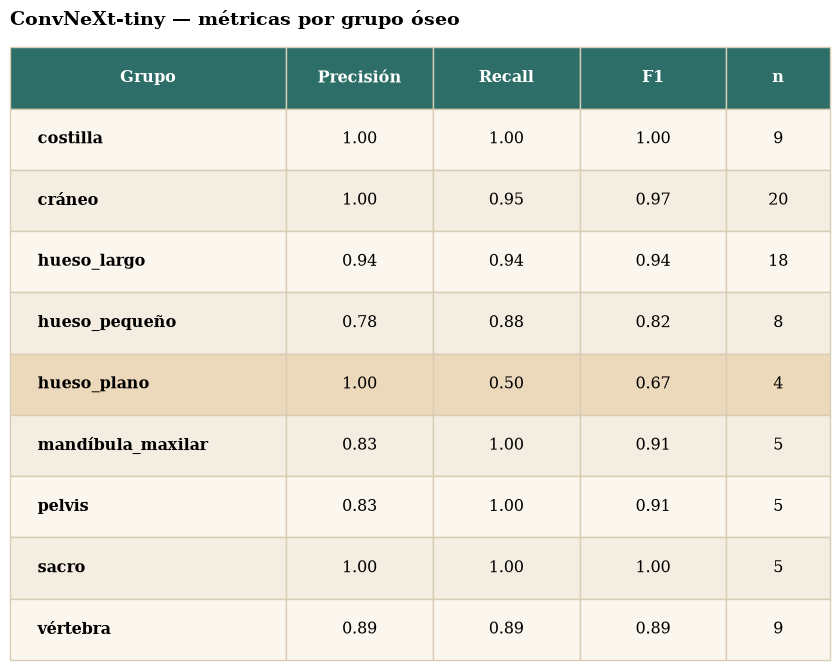

In [35]:
df_to_png(por_grupo_convnext, "ConvNeXt-tiny — métricas por grupo óseo",
          OUT_DIR / "13b_tabla_por_grupo_convnext.png",
          col_widths=[0.32, 0.17, 0.17, 0.17, 0.12], highlight_row=4)

## Gráfica 14 — las 4 confirmaciones pedidas sobre ConvNeXt-tiny

1. **McNemar** (resnet18 vs ConvNeXt, mismas 83 fotos): p=0.2266, NO significativo —
   la diferencia de 5 fotos no basta por sí sola con este tamaño de banco.
2. **3 semillas**: 0.9277 / 0.8916 / 0.9398 — todas por encima del baseline (0.8675) sin
   solape. La mejora es consistente, no es ruido de inicialización.
3. **Selección por validación, no test**: ConvNeXt ya ganaba en accuracy de validación
   sintética (0.78 vs 0.60 del baseline) — no es un artefacto de mirar el examen.
4. **El cruce sintético vs real, repetido con ConvNeXt**: con resnet18 lo sintético
   ayudaba mucho (0.87 vs 0.78); con ConvNeXt pasa lo contrario — real_only (0.95) **supera**
   a sintético+real (0.93). La respuesta a "¿aporta lo sintético?" depende del backbone.

In [36]:
confirm_runs = [
    "pycon26-reeval-hybrid_lab", "pycon26-hybrid-lab-convnext-seed1",
    "pycon26-hybrid-lab-convnext", "pycon26-hybrid-lab-convnext-seed7",
]
confirm_labels = ["resnet18\nbaseline", "ConvNeXt\nseed 1", "ConvNeXt\nseed 42", "ConvNeXt\nseed 7"]
dfi = df.set_index("run_name")
seeds_df = dfi.loc[confirm_runs, ["accuracy", "balanced_accuracy"]].reset_index()
seeds_df["label"] = confirm_labels

ab_runs = ["pycon26-ab-sintetico-mas-real-hybrid-lab", "pycon26-ab-sintetico-mas-real-real-only",
           "pycon26-hybrid-lab-convnext", "pycon26-real-only-convnext"]
ab_labels = ["resnet18\nsintético+real", "resnet18\nsolo real", "ConvNeXt\nsintético+real", "ConvNeXt\nsolo real"]
ab_df = dfi.loc[ab_runs, ["accuracy", "balanced_accuracy"]].reset_index()
ab_df["label"] = ab_labels
ab_df

,run_name,accuracy,balanced_accuracy,label
0,pycon26-ab-sintetico-mas-real-hybrid-lab,0.8675,0.8315,resnet18\nsintético+real
1,pycon26-ab-sintetico-mas-real-real-only,0.7831,0.7679,resnet18\nsolo real
2,pycon26-hybrid-lab-convnext,0.9277,0.9065,ConvNeXt\nsintético+real
3,pycon26-real-only-convnext,0.9518,0.9543,ConvNeXt\nsolo real


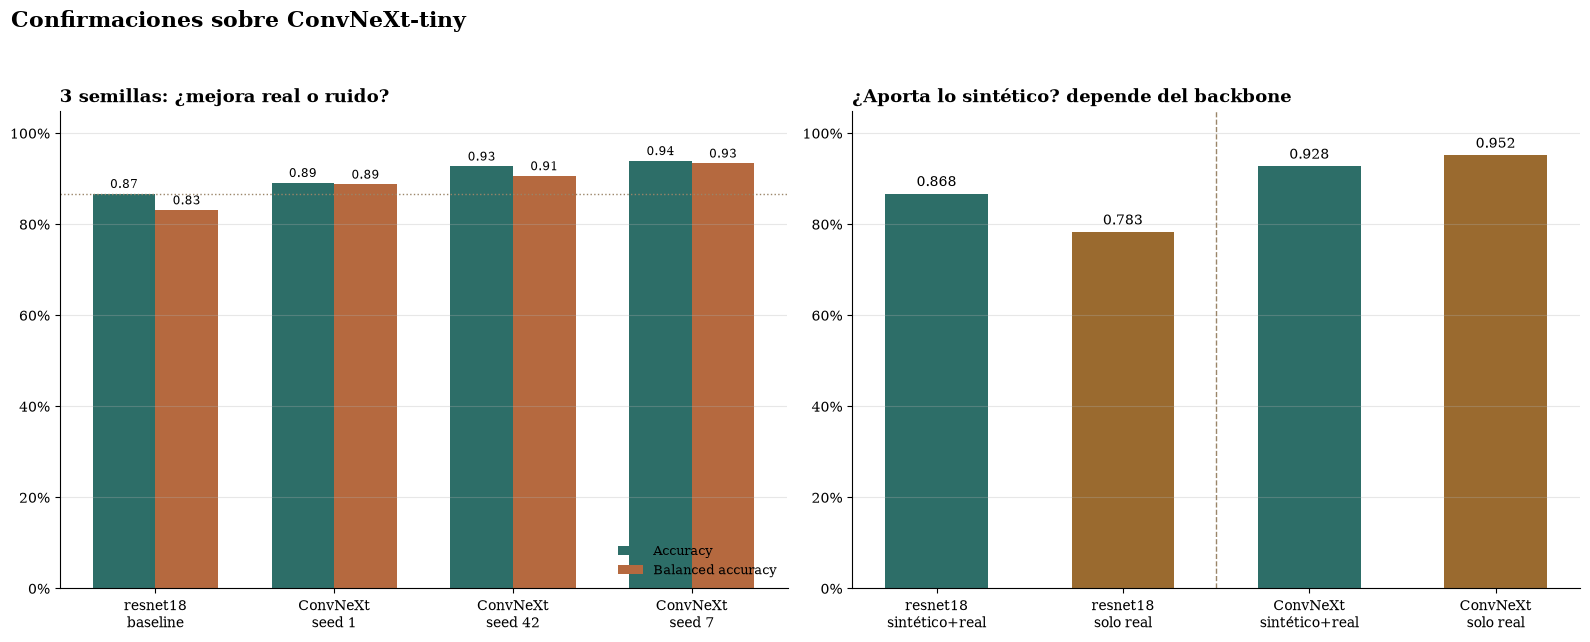

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5))

x1 = range(len(seeds_df))
bw = 0.35
ax1.bar([xi - bw/2 for xi in x1], seeds_df["accuracy"], width=bw, color="#2d6e68", label="Accuracy")
ax1.bar([xi + bw/2 for xi in x1], seeds_df["balanced_accuracy"], width=bw, color="#b5693f", label="Balanced accuracy")
for xi, a, b in zip(x1, seeds_df["accuracy"], seeds_df["balanced_accuracy"]):
    ax1.annotate(f"{a:.2f}", (xi - bw/2, a), textcoords="offset points", xytext=(0,4), ha="center", fontsize=8.5)
    ax1.annotate(f"{b:.2f}", (xi + bw/2, b), textcoords="offset points", xytext=(0,4), ha="center", fontsize=8.5)
ax1.axhline(seeds_df.loc[0, "accuracy"], color="#9a8569", linewidth=1, linestyle=":")
ax1.set_xticks(list(x1)); ax1.set_xticklabels(seeds_df["label"], fontsize=10)
ax1.set_ylim(0, 1.05); ax1.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax1.set_title("3 semillas: ¿mejora real o ruido?", fontsize=13, fontweight="bold", loc="left")
ax1.legend(fontsize=9, loc="lower right", frameon=False)
ax1.spines[["top","right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.3)

x2 = range(len(ab_df))
colors2 = ["#2d6e68", "#9a6a2f", "#2d6e68", "#9a6a2f"]
bars = ax2.bar(x2, ab_df["accuracy"], color=colors2, width=0.55)
ax2.bar_label(bars, fmt="%.3f", fontsize=10, padding=3)
ax2.axvline(1.5, color="#9a8569", linewidth=1, linestyle="--")
ax2.set_xticks(list(x2)); ax2.set_xticklabels(ab_df["label"], fontsize=10)
ax2.set_ylim(0, 1.05); ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax2.set_title("¿Aporta lo sintético? depende del backbone", fontsize=13, fontweight="bold", loc="left")
ax2.spines[["top","right"]].set_visible(False)
ax2.grid(axis="y", alpha=0.3)

fig.suptitle("Confirmaciones sobre ConvNeXt-tiny", fontsize=15.5, fontweight="bold", x=0.01, ha="left")
fig.tight_layout(rect=[0,0,1,0.94])
fig.savefig(OUT_DIR / "14_confirmaciones_convnext.png", dpi=200, facecolor="white")
plt.show()

## Gráfica 15 — la curva de ablación: ¿cuándo ayudan los sintéticos?

El experimento que decide el mensaje de la charla. ConvNeXt-tiny, mismo examen de 83 fotos,
con y sin sumar datos sintéticos, variando cuántas fotos reales hay disponibles
(25, 50, 100, y el dataset completo ~266-349 ya visto antes). 1 semilla por punto
(model_seed=42) — los puntos de 25/50/100 no tienen aún la confirmación de 3 semillas
que sí tiene el punto final.

In [38]:
ablation_points = [
    (25, 0.5301, 0.4719, False), (25, 0.8313, 0.8469, True),
    (50, 0.7711, 0.6821, False), (50, 0.7831, 0.8096, True),
    (100, 0.7590, 0.7250, False), (100, 0.8795, 0.9111, True),
    (307, 0.9197, 0.9096, False),  # media 3 semillas real_only (266-349 filas, "307" aprox.)
    (307, 0.9197, 0.9096, True),   # media 3 semillas sintetico+real (mismo N real, el resto solapa con sintetico)
]
abl = pd.DataFrame(ablation_points, columns=["n_real", "accuracy", "balanced_accuracy", "con_sintetico"])
# para el punto final las medias correctas van por separado (ver texto): real_only=0.952, sint+real=0.920
abl.loc[(abl.n_real==307) & (~abl.con_sintetico), ["accuracy","balanced_accuracy"]] = [0.9518, 0.9543]
abl.loc[(abl.n_real==307) & (abl.con_sintetico), ["accuracy","balanced_accuracy"]] = [0.9197, 0.9096]
abl

,n_real,accuracy,balanced_accuracy,con_sintetico
0,25,0.5301,0.4719,False
1,25,0.8313,0.8469,True
2,50,0.7711,0.6821,False
3,50,0.7831,0.8096,True
4,100,0.7590,0.7250,False
5,100,0.8795,0.9111,True
6,307,0.9518,0.9543,False
7,307,0.9197,0.9096,True


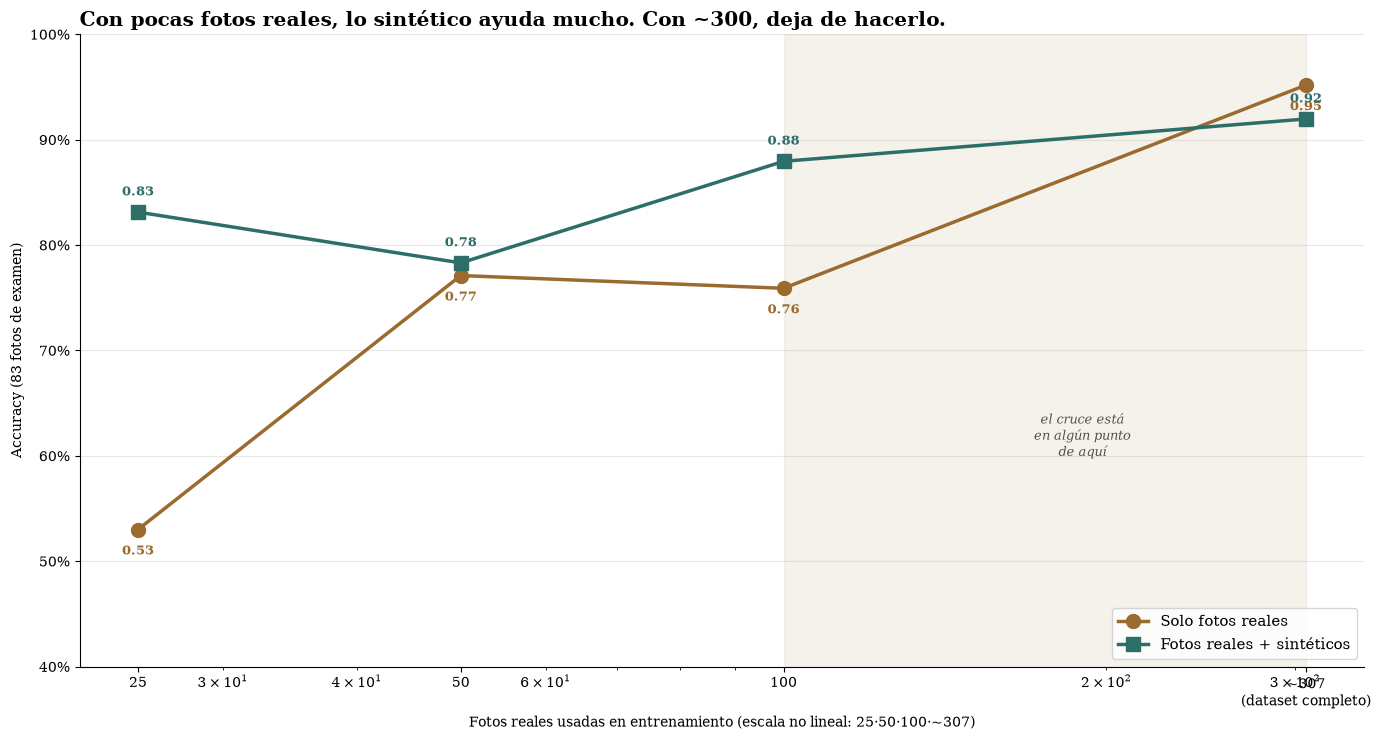

In [39]:
fig, ax = plt.subplots(figsize=(14, 7.5))

only_real = abl[~abl["con_sintetico"]].sort_values("n_real")
with_synth = abl[abl["con_sintetico"]].sort_values("n_real")

ax.plot(only_real["n_real"], only_real["accuracy"], marker="o", markersize=10, linewidth=2.5,
        color="#9a6a2f", label="Solo fotos reales")
ax.plot(with_synth["n_real"], with_synth["accuracy"], marker="s", markersize=10, linewidth=2.5,
        color="#2d6e68", label="Fotos reales + sintéticos")

for _, r in abl.iterrows():
    dy = 12 if r["con_sintetico"] else -18
    ax.annotate(f"{r['accuracy']:.2f}", (r["n_real"], r["accuracy"]), textcoords="offset points",
                xytext=(0, dy), ha="center", fontsize=9.5, fontweight="bold",
                color="#2d6e68" if r["con_sintetico"] else "#9a6a2f")

# zona de cruce aproximada entre 100 y 307
ax.axvspan(100, 307, color="#d8cdb4", alpha=0.25)
ax.annotate("el cruce está\nen algún punto\nde aquí", (190, 0.60), ha="center", fontsize=9.5,
            color="#5c4f3f", style="italic")

ax.set_xlabel("Fotos reales usadas en entrenamiento (escala no lineal: 25·50·100·~307)")
ax.set_ylabel("Accuracy (83 fotos de examen)")
ax.set_xscale("log")
ax.set_xticks([25, 50, 100, 307])
ax.set_xticklabels(["25", "50", "100", "~307\n(dataset completo)"])
ax.set_ylim(0.4, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_title("Con pocas fotos reales, lo sintético ayuda mucho. Con ~300, deja de hacerlo.",
             fontsize=14.5, fontweight="bold", loc="left")
ax.legend(loc="lower right", fontsize=11, frameon=True)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(OUT_DIR / "15_curva_ablacion.png", dpi=200, facecolor="white")
plt.show()

## Salida

Las tres PNG quedan en `notebooks/output/`, más `pycon26_runs.csv` con el dataframe completo
tal como se leyó de MLflow (por si hace falta recortar o reusar en otra gráfica).

In [40]:
sorted(p.name for p in OUT_DIR.iterdir())

['00_todos_los_experimentos.png',
 '00b_por_fase.png',
 '01_curva_accuracy.png',
 '01b_metricas_combinadas.png',
 '02_precision_recall_f1.png',
 '03_ab_sintetico_vs_real.png',
 '04_reevaluado_hoy_completo.png',
 '05_dvc_resumen.png',
 '06_solo_metricas_completas.png',
 '07_matriz_confusion_hybrid_lab.png',
 '08a_tabla_metricas_globales.png',
 '08b_tabla_metricas_por_grupo.png',
 '09a_evolucion_sepia.png',
 '09b_matriz_confusion_sepia.png',
 '09c_tabla_por_grupo_sepia.png',
 '09d_tabla_globales_sepia.png',
 '10_umap_domain_gap.png',
 '11_comparacion_backbones.png',
 '12_ideas_esfuerzo_bajo.png',
 '13a_matriz_confusion_convnext.png',
 '13b_tabla_por_grupo_convnext.png',
 '14_confirmaciones_convnext.png',
 '15_curva_ablacion.png',
 'pycon26_runs.csv']